# Grafici per la tesi

Rigenera con colori uniformi i grafici scelti con Irene e li salva in `corner_tesi/`.
Legge solo catene gia salvate: **nessun sampling**.

Colori:

| | colore | codice |
|---|---|---|
| dati reali | blu | `#2E86AB` |
| dati reali, seconda catena | blu scuro | `#264653` |
| simulazioni | arancio | `#F4A261` |
| simulazioni, seconda catena | viola | `#6A4C93` |
| DR2new+ ed Enterprise | verde | `#009E73` |
| valori iniettati | nero | `#222222` |

In [86]:
import numpy as np
import os

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import corner

os.makedirs('corner_tesi', exist_ok=True)

REALE   = '#2E86AB'   # blu
REALE_2 = '#264653'   # blu scuro
SIM     = '#F4A261'   # arancio
SIM_2   = '#6A4C93'   # viola
ENT     = '#009E73'   # verde: DR2new+ ed Enterprise

In [87]:
def load_chain(path):
    c = np.loadtxt(path)[:, :-4]
    return c[len(c)//4:]           # rimuovo il 25% di burn-in

# ordine delle colonne delle catene (lo stesso di logL.params nei notebook)
params_6  = ['J1640+2224_dm_gp_gamma', 'J1640+2224_dm_gp_log10_A',
             'J1640+2224_red_noise_gamma', 'J1640+2224_red_noise_log10_A',
             'J1640+2224_sv_gp_gamma', 'J1640+2224_sv_gp_log10_A']
params_8  = ['J1640+2224_band_noise_gamma', 'J1640+2224_band_noise_log10_A'] + params_6
params_af = ['J1640+2224_sv_gp_alpha'] + params_6

# valori iniettati nelle simulazioni
truths_dict = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
}

## 1. DR2low: Discovery vs Enterprise (notebook 01)

In [88]:
chain     = load_chain('./test/chain_1.txt')          # Discovery, DR2low reali, alpha = 4.0
chain_ent = load_chain('./spna_J1640/chain_1.txt')    # Enterprise, gia nell ordine di Discovery
print(chain.shape, chain_ent.shape)

(75001, 6) (75001, 6)


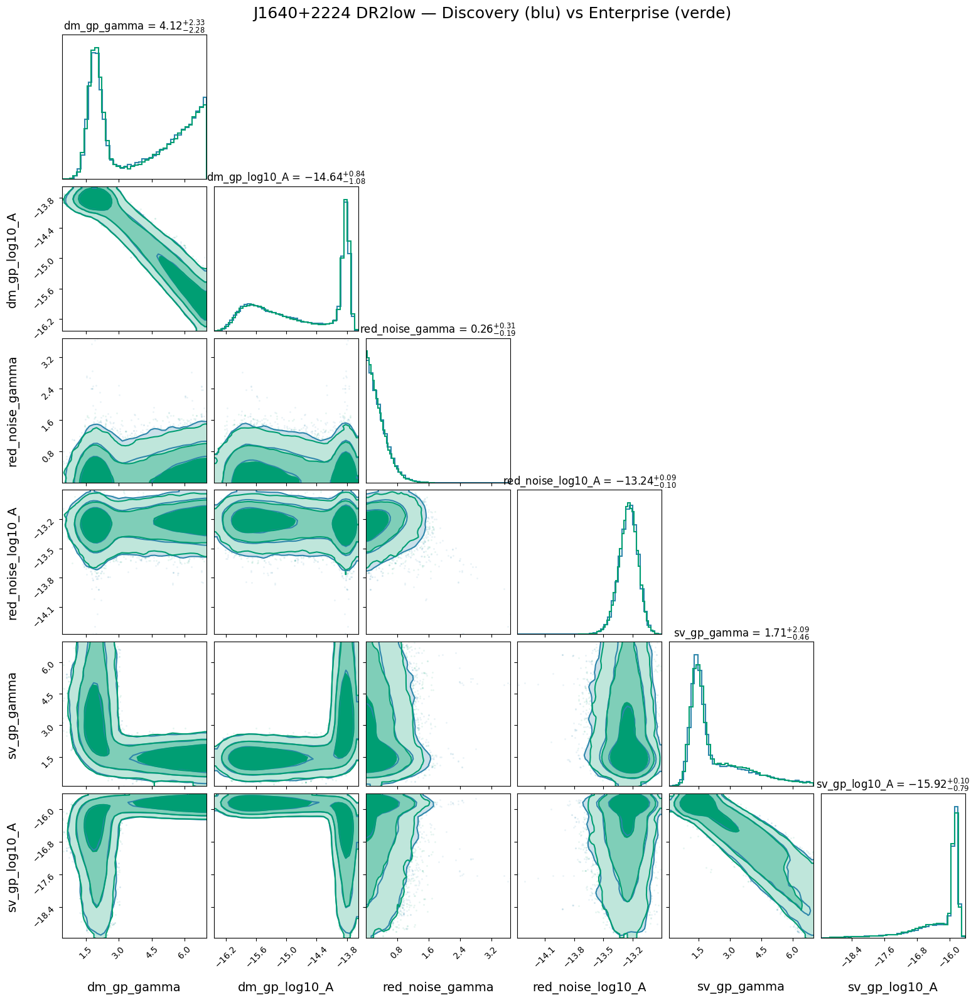

In [89]:
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_ent,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=ENT,
    hist_kwargs={'color': ENT, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low — Discovery (blu) vs Enterprise (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/01_discovery_vs_enterprise.png', dpi=150, bbox_inches='tight')

## 2. DR2low vs DR2new+ (notebook 02)

In [90]:
chain_dr2new = load_chain('./test_DR2newplus_6par/chain_1.txt')
chain_dr2new.shape

(75001, 6)

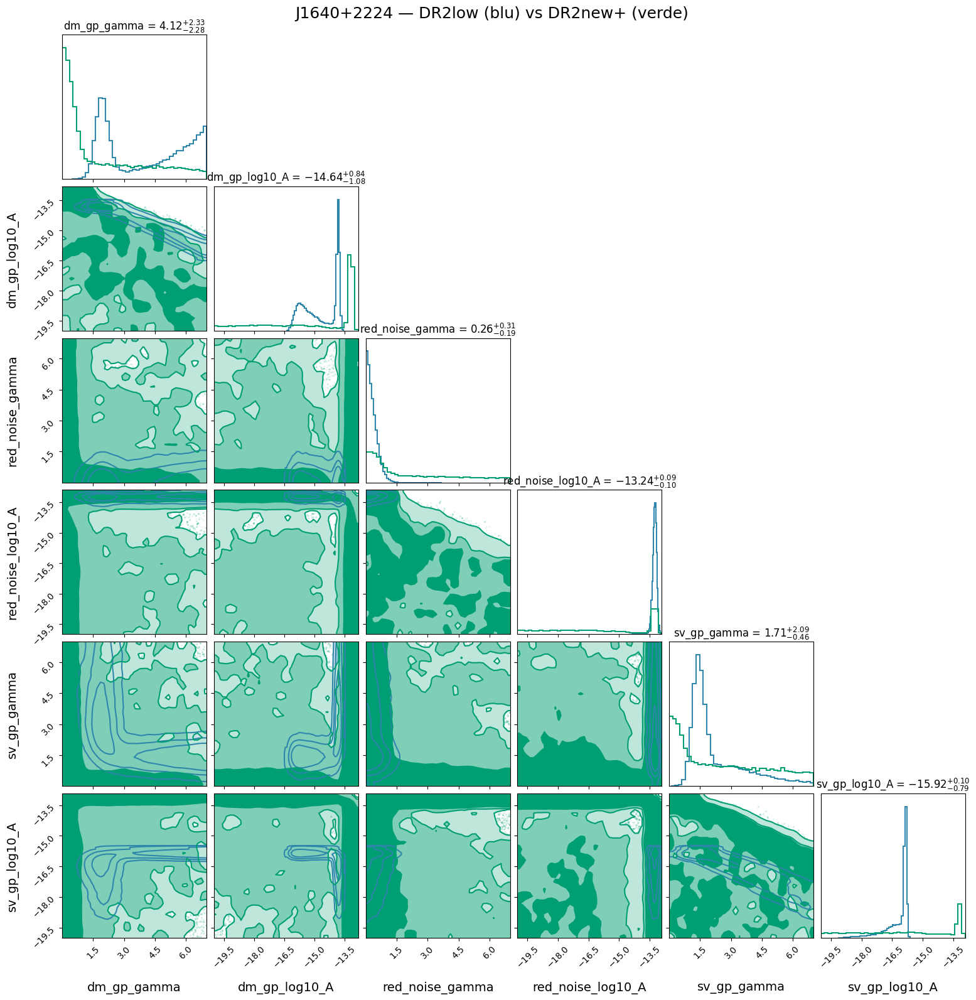

In [91]:
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_dr2new,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=ENT,
    hist_kwargs={'color': ENT, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — DR2low (blu) vs DR2new+ (verde)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/02_DR2low_vs_DR2newplus.png', dpi=150, bbox_inches='tight')

## 3. Dati reali con band noise nel modello (notebook 20)

In [92]:
chain_real_6par = load_chain('./test_real_sv44/chain_1.txt')        # alpha = 4.4, 6 par
chain_real_8par = load_chain('./test_real_bn_bnmodel/chain_1.txt')  # alpha = 4.4, 8 par
print(chain_real_6par.shape, chain_real_8par.shape)

(75001, 6) (75001, 8)


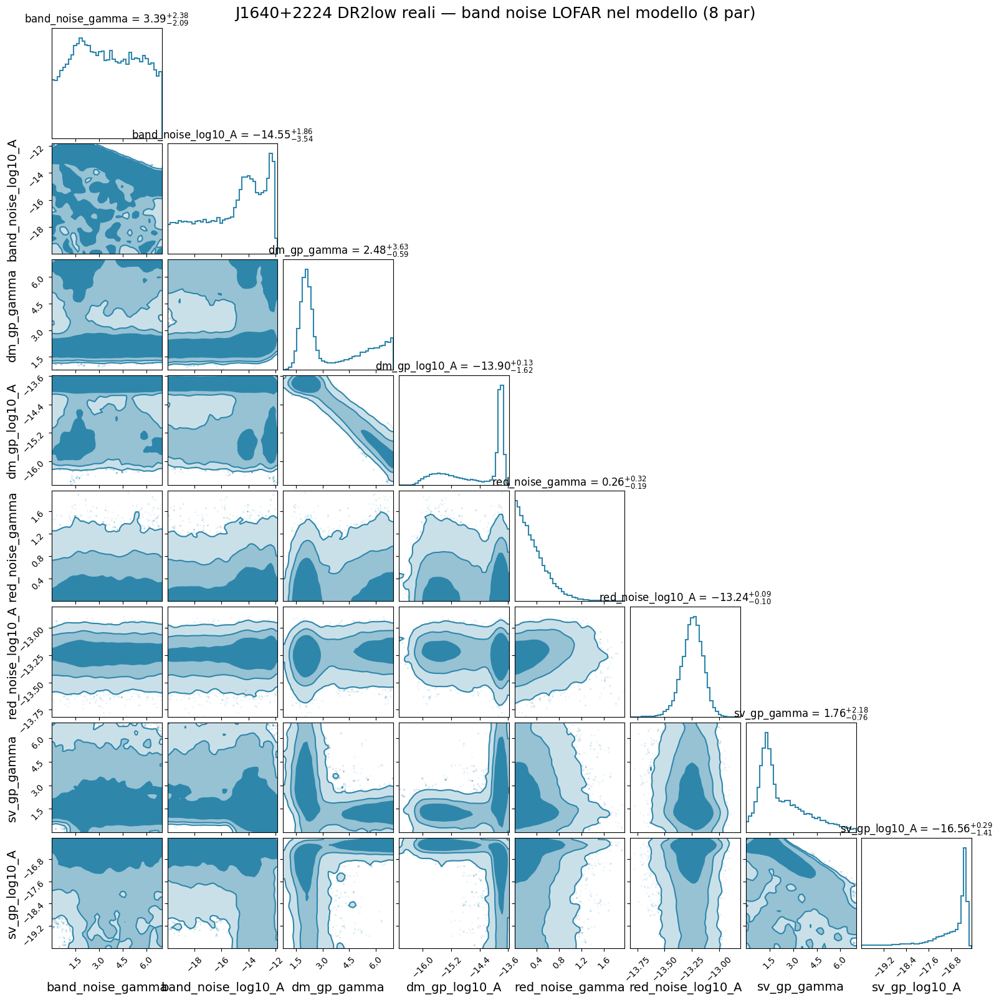

In [93]:
clean_labels = [name.replace('J1640+2224_', '') for name in params_8]

fig = corner.corner(
    chain_real_8par,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — band noise LOFAR nel modello (8 par)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/03_reali_8par_band.png', dpi=150, bbox_inches='tight')

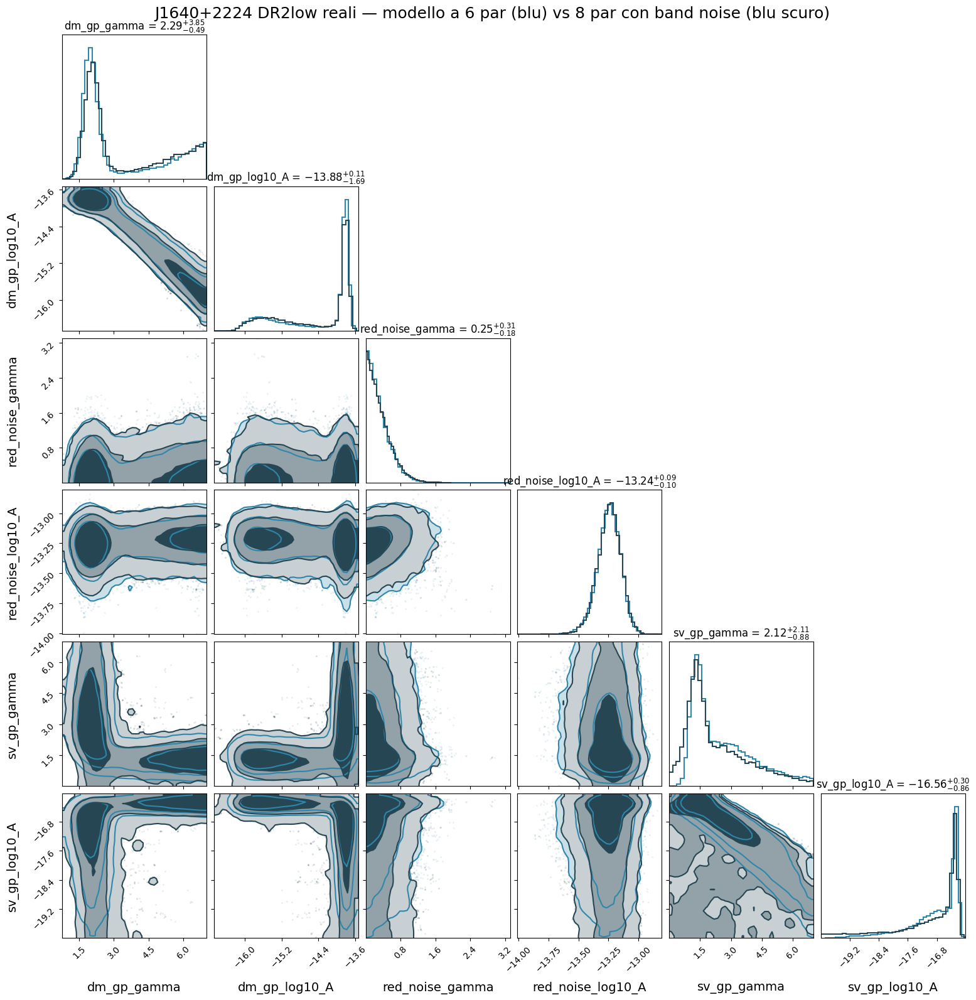

In [94]:
# dalla catena a 8 par tengo solo le 6 colonne comuni
chain_real_8par_comuni = chain_real_8par[:, [params_8.index(p) for p in params_6]]

clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_real_6par,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_real_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=REALE_2,
    hist_kwargs={'color': REALE_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — modello a 6 par (blu) vs 8 par con band noise (blu scuro)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/03_reali_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## 4. Alpha libero, dati reali (notebook 15)

In [95]:
chain_real_af = load_chain('./test_real_alphafree_ws/chain_1.txt')           # 7 par, alpha libero
chain_sim_af  = load_chain('./test_sim_sv44_alphafree_ws/chain_1.txt')       # sim alpha = 4.4 iniettato, alpha libero
print(chain_real_af.shape, chain_sim_af.shape)

(75001, 7) (75001, 7)


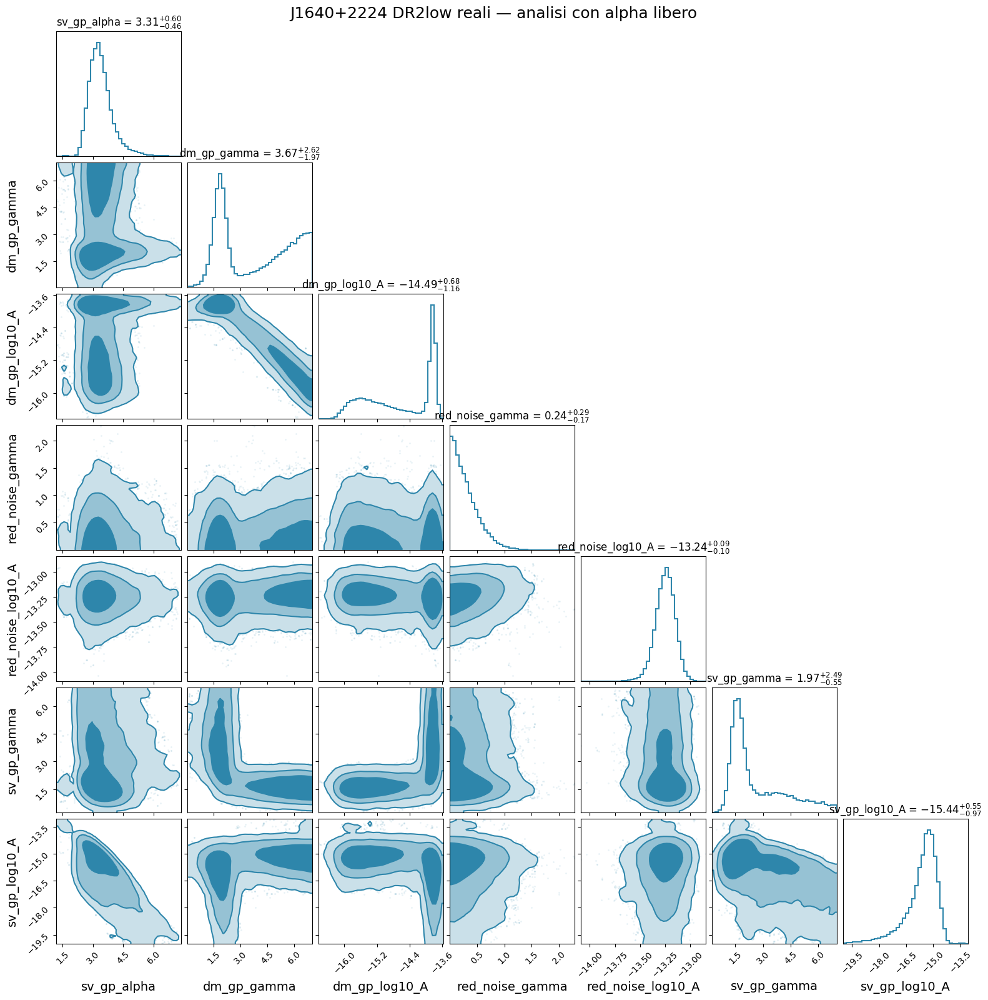

In [96]:
clean_labels = [name.replace('J1640+2224_', '') for name in params_af]

fig = corner.corner(
    chain_real_af,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — analisi con alpha libero',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/04_reali_alphafree.png', dpi=150, bbox_inches='tight')

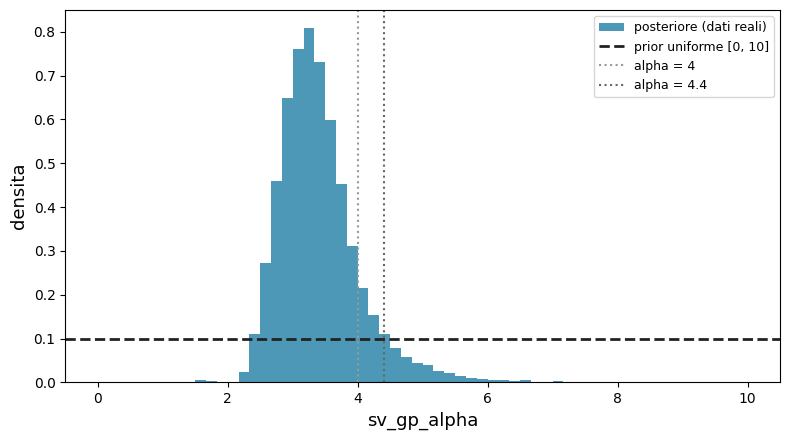

In [97]:
a_s = chain_real_af[:, params_af.index('J1640+2224_sv_gp_alpha')]
prior_lo, prior_hi = 0.0, 10.0

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(a_s, bins=60, range=(prior_lo, prior_hi), density=True, color=REALE,
        alpha=0.85, label='posteriore (dati reali)')
ax.axhline(1.0/(prior_hi - prior_lo), color='#222222', ls='--', lw=2,
           label='prior uniforme [0, 10]')
ax.axvline(4.0, color='#999999', ls=':', lw=1.5, label='alpha = 4')
ax.axvline(4.4, color='#666666', ls=':', lw=1.5, label='alpha = 4.4')
ax.set_xlabel('sv_gp_alpha', fontsize=13)
ax.set_ylabel('densita', fontsize=13)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig('corner_tesi/04_alpha_posteriore_vs_prior.png', dpi=150, bbox_inches='tight')

nu_eff ~ 146 MHz, pendenza attesa -0.98, misurata -1.05


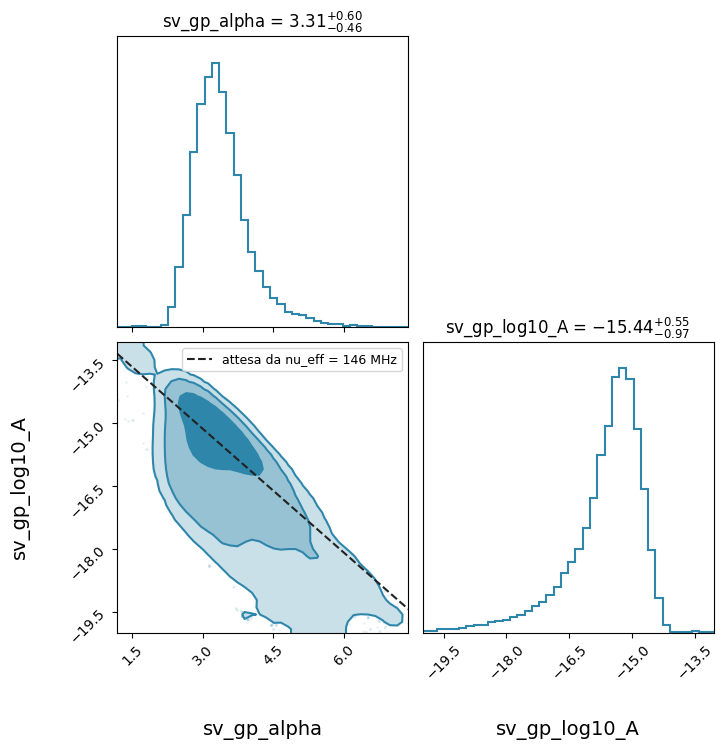

In [98]:
# degenerazione alpha - log10_A dello scattering, con la retta attesa dalla frequenza efficace
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9]

f_toa = np.asarray(psr.freqs)
sig   = np.asarray(psr.toaerrs)
lA_s  = chain_real_af[:, params_af.index('J1640+2224_sv_gp_log10_A')]
a_med = float(np.median(a_s))

w = (1400.0 / f_toa)**(2 * a_med) / sig**2
slope  = -np.sum(w * np.log10(1400.0 / f_toa)) / np.sum(w)
nu_eff = 1400.0 / 10**(-slope)
print(f'nu_eff ~ {nu_eff:.0f} MHz, pendenza attesa {slope:.2f}, misurata {np.polyfit(a_s, lA_s, 1)[0]:.2f}')

fig = corner.corner(
    np.column_stack([a_s, lA_s]),
    labels=['sv_gp_alpha', 'sv_gp_log10_A'],
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);
ax = fig.axes[2]   # pannello 2D in basso a sinistra
xx = np.linspace(a_s.min(), a_s.max(), 100)
ax.plot(xx, float(np.median(lA_s)) + slope * (xx - a_med), color='#222222', ls='--', lw=1.5,
        label=f'attesa da nu_eff = {nu_eff:.0f} MHz')
ax.legend(fontsize=9)
fig.set_size_inches(8, 8)
fig.savefig('corner_tesi/04_alphafree_degenerazione.png', dpi=150, bbox_inches='tight')

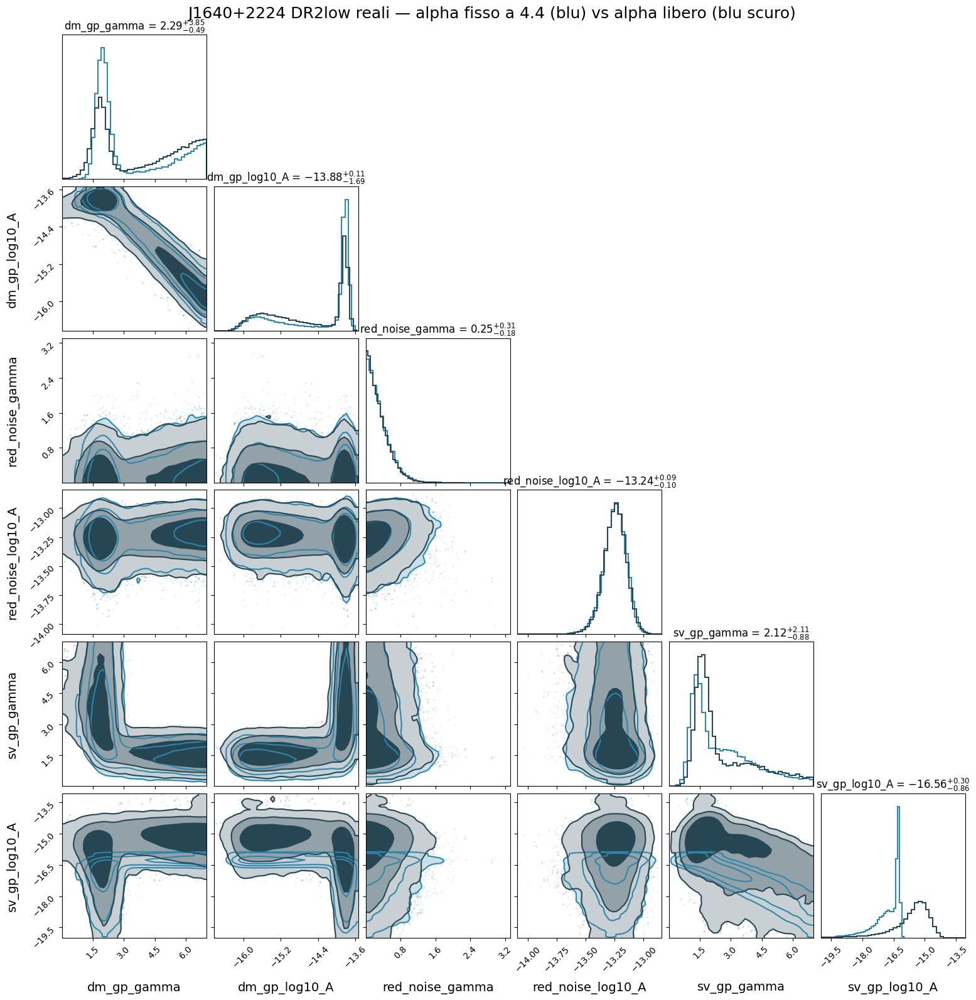

In [99]:
# colonne della catena alpha libero riordinate come i 6 parametri standard
chain_real_af_6 = chain_real_af[:, [params_af.index(p) for p in params_6]]

clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_real_6par,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_real_af_6,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=REALE_2,
    hist_kwargs={'color': REALE_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 DR2low reali — alpha fisso a 4.4 (blu) vs alpha libero (blu scuro)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/04_reali_alpha44_vs_alphafree.png', dpi=150, bbox_inches='tight')

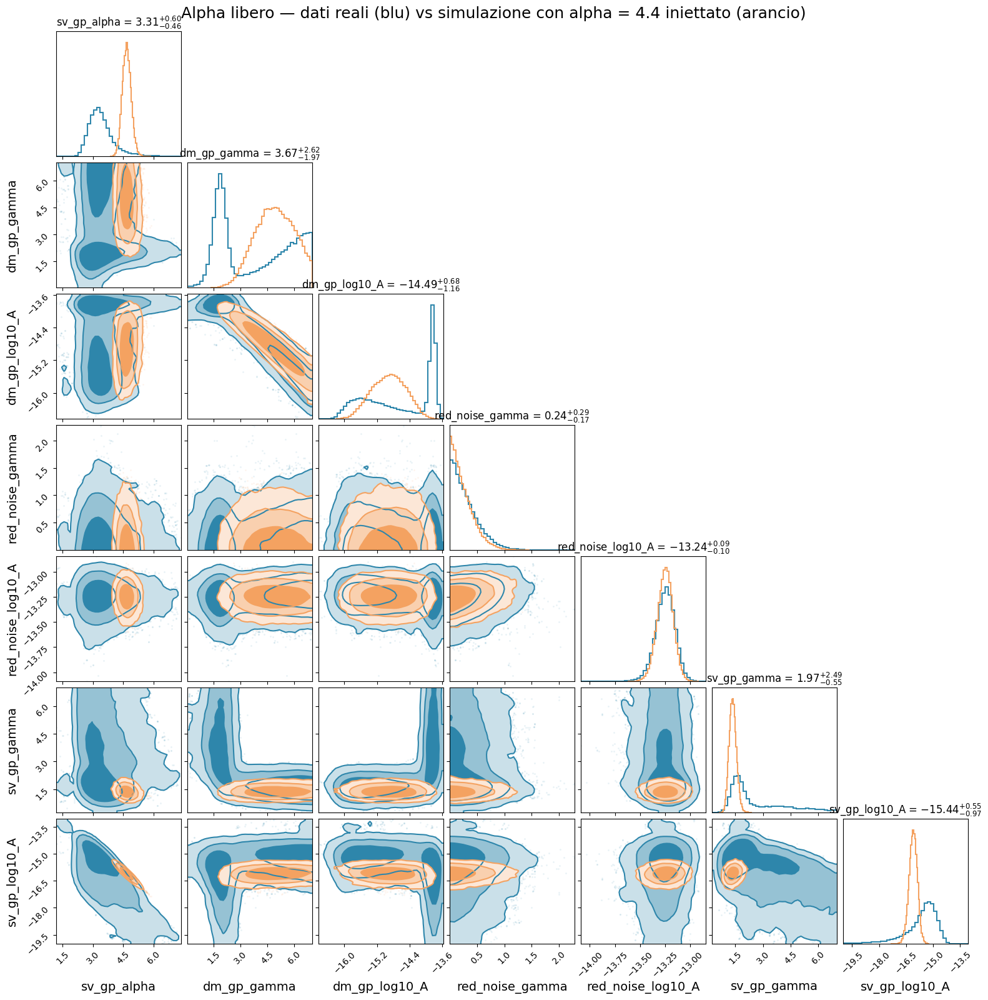

In [100]:
clean_labels = [name.replace('J1640+2224_', '') for name in params_af]

# Primo corner
fig = corner.corner(
    chain_real_af,
    labels=clean_labels,
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_sim_af,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('Alpha libero — dati reali (blu) vs simulazione con alpha = 4.4 iniettato (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/04_reali_vs_sim_alphafree.png', dpi=150, bbox_inches='tight')

## 5. Reali vs simulati, 6 par, senza GWB e senza band (notebook 03)

In [101]:
chain_sim = load_chain('./test_sim/chain_1.txt')
chain_sim.shape

(75001, 6)

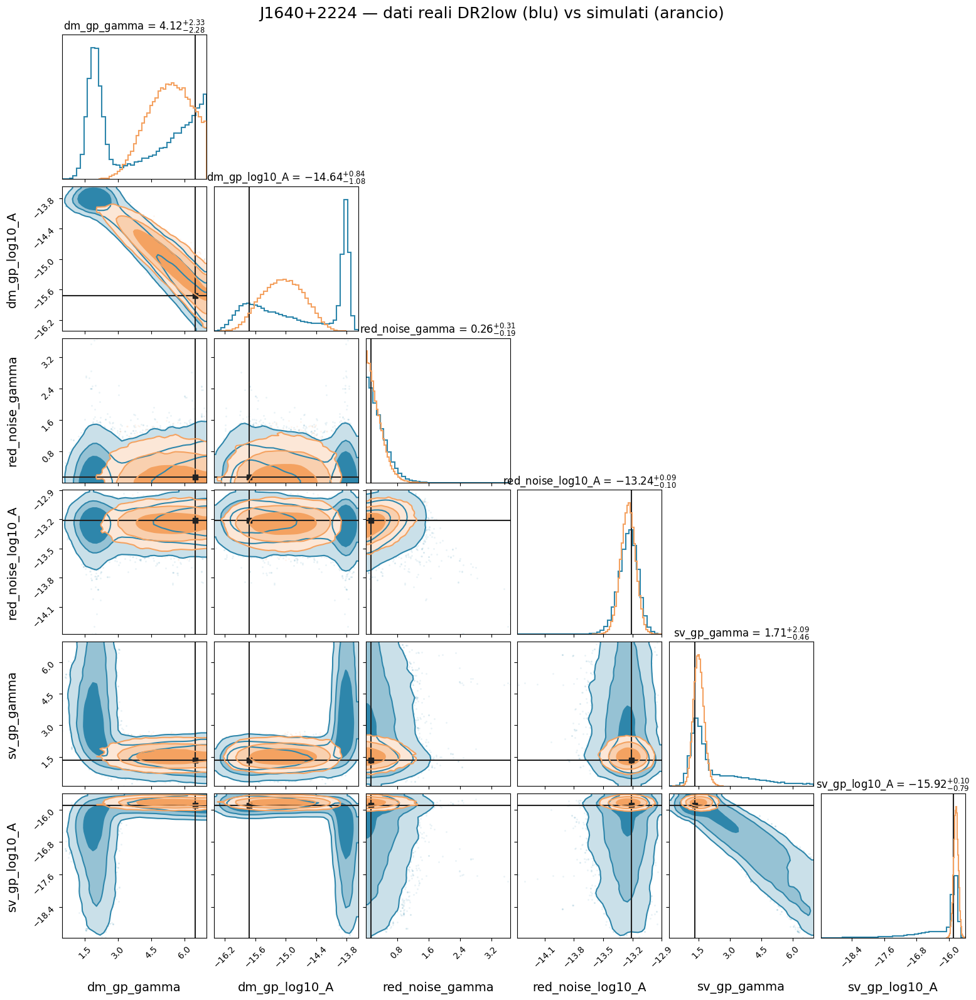

In [102]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_sim,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — dati reali DR2low (blu) vs simulati (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/05_reali_vs_simulati.png', dpi=150, bbox_inches='tight')

## 6. GWB a tutte le ampiezze (notebook 04)

Simulazioni con alpha = 4.0, analizzate con il modello a 6 par (GWB non modellato). La simulazione senza GWB
di riferimento e `test_sim2`, come nel notebook 04.

In [103]:
chain_sim2     = load_chain('./test_sim2/chain_1.txt')          # senza GWB
chain_gwb_A145 = load_chain('./test_sim_gwb_A145/chain_1.txt')  # GWB log10_A = -14.5
chain_gwb_A150 = load_chain('./test_sim_gwb/chain_1.txt')       # GWB log10_A = -15.0
chain_gwb_A155 = load_chain('./test_sim_gwb_A155/chain_1.txt')  # GWB log10_A = -15.5
print(chain_sim2.shape, chain_gwb_A145.shape, chain_gwb_A150.shape, chain_gwb_A155.shape)

(75001, 6) (75001, 6) (75001, 6) (75001, 6)


### GWB a -14.5

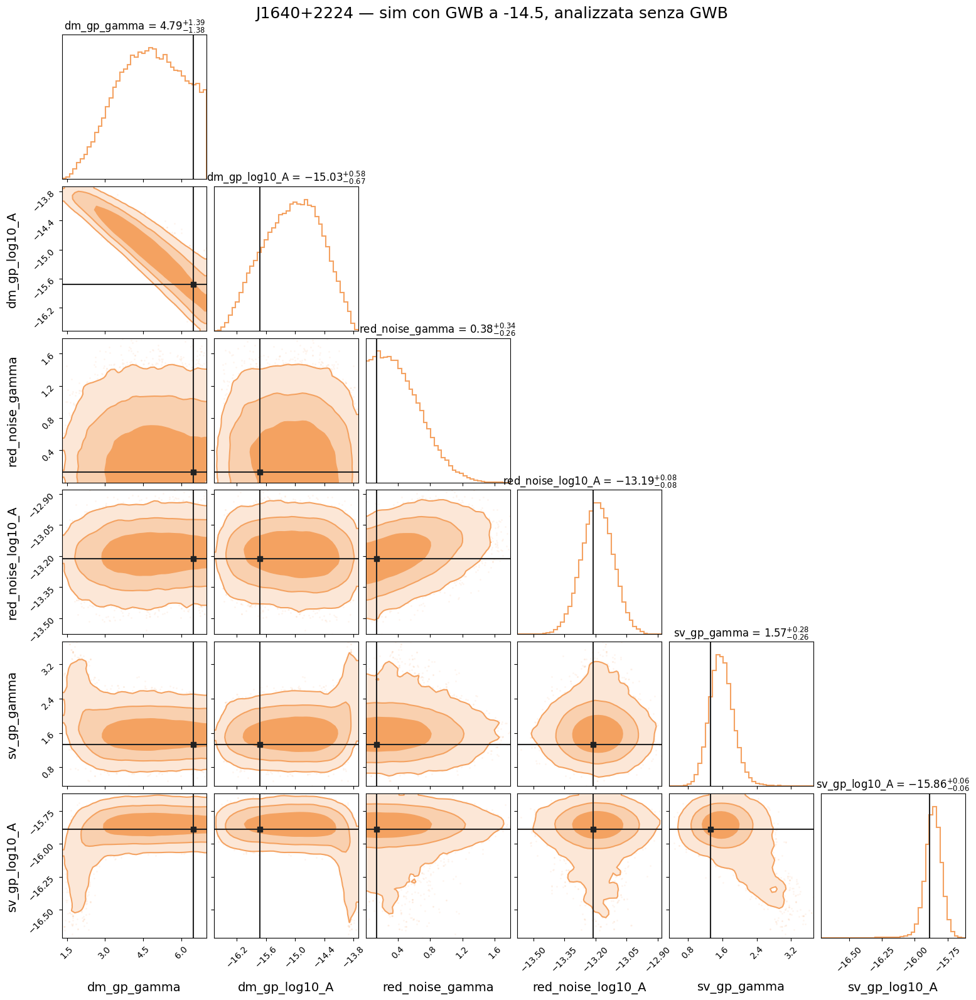

In [104]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

fig = corner.corner(
    chain_gwb_A145,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim con GWB a -14.5, analizzata senza GWB',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_gwb_A145.png', dpi=150, bbox_inches='tight')

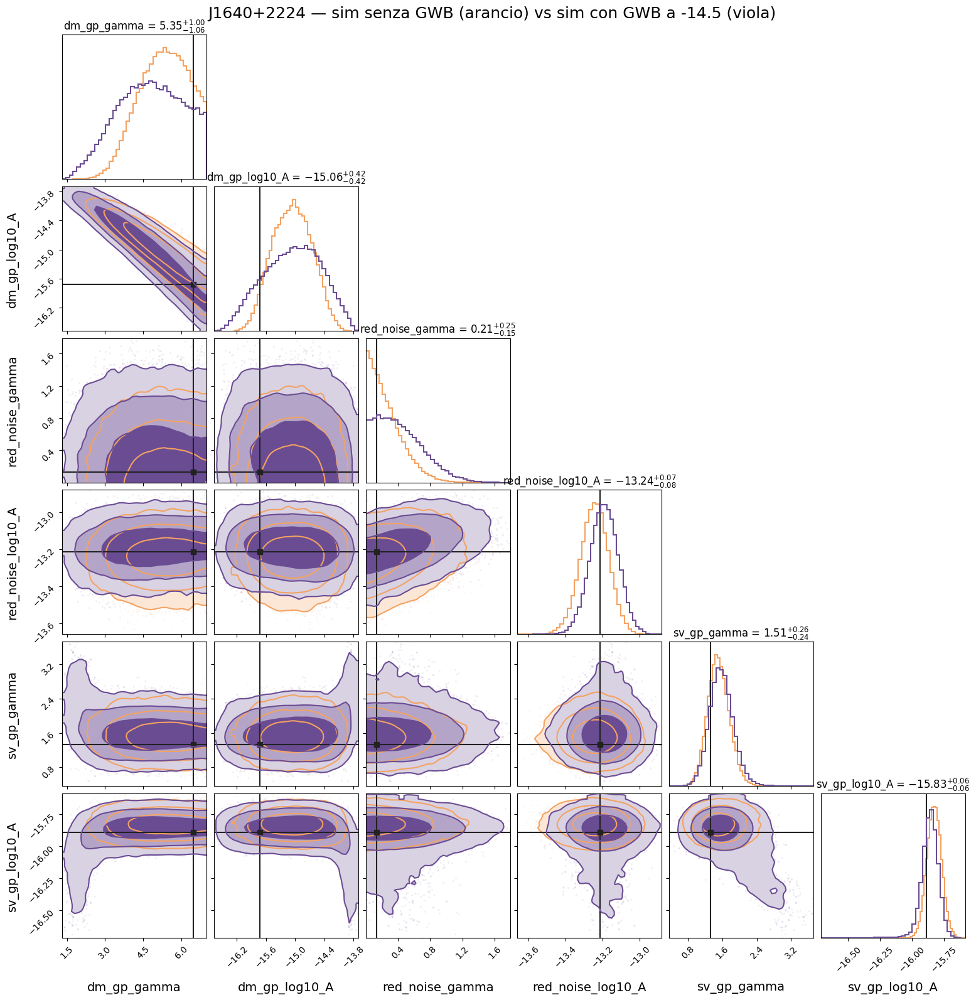

In [105]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_sim2,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A145,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim senza GWB (arancio) vs sim con GWB a -14.5 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_noGWB_vs_gwb_A145.png', dpi=150, bbox_inches='tight')

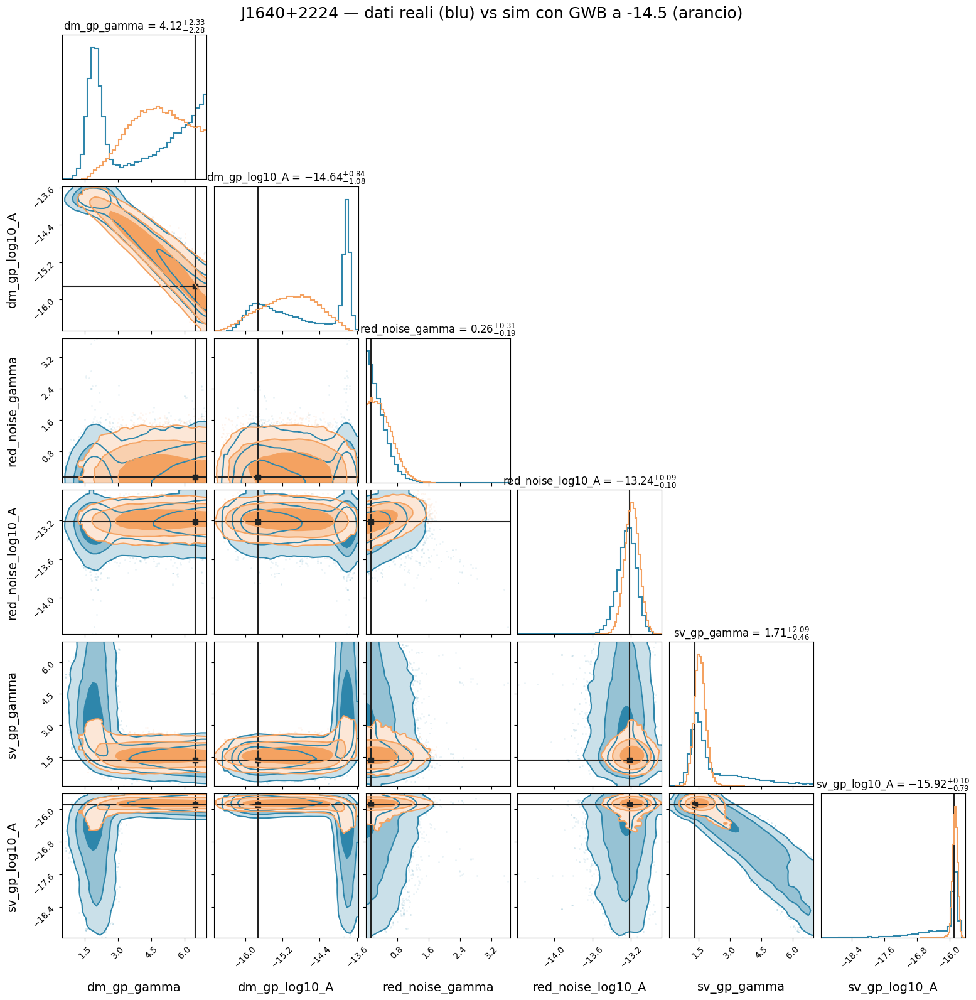

In [106]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A145,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — dati reali (blu) vs sim con GWB a -14.5 (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_reali_vs_sim_gwb_A145.png', dpi=150, bbox_inches='tight')

### GWB a -15.0

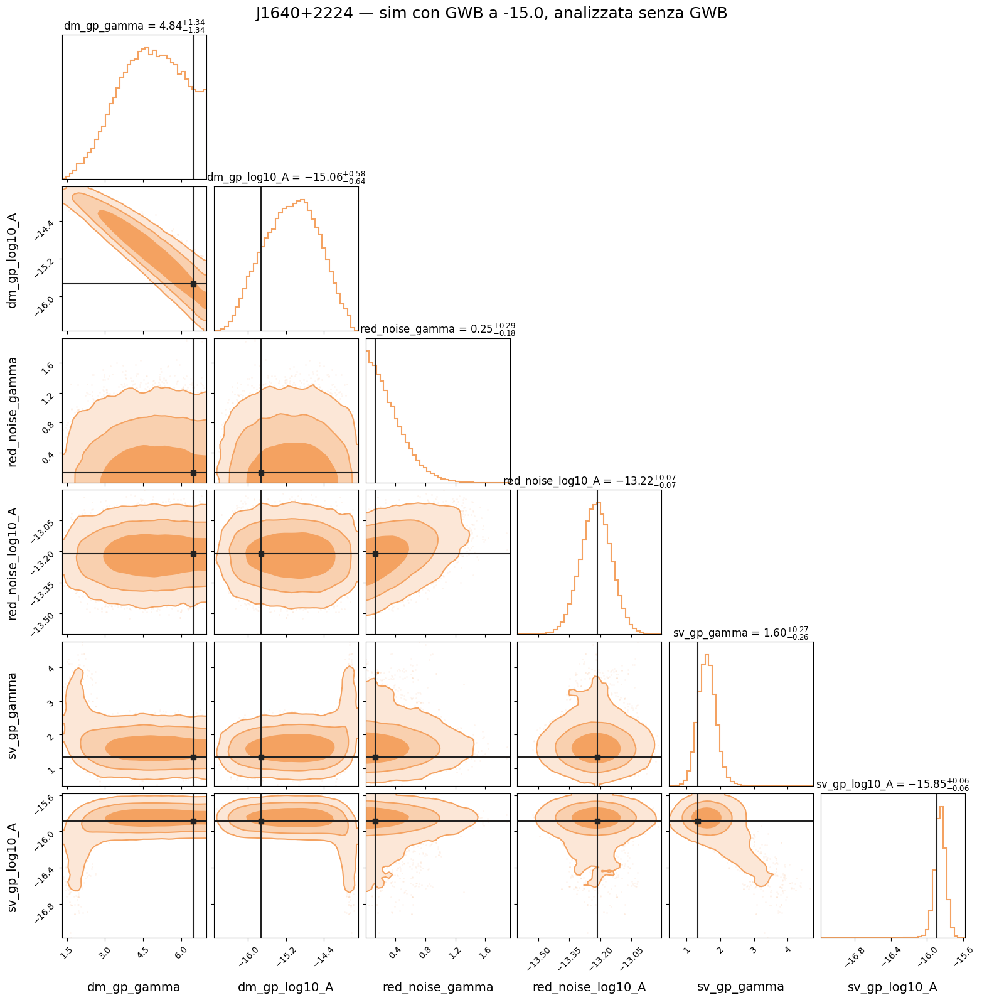

In [107]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

fig = corner.corner(
    chain_gwb_A150,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim con GWB a -15.0, analizzata senza GWB',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_gwb_A150.png', dpi=150, bbox_inches='tight')

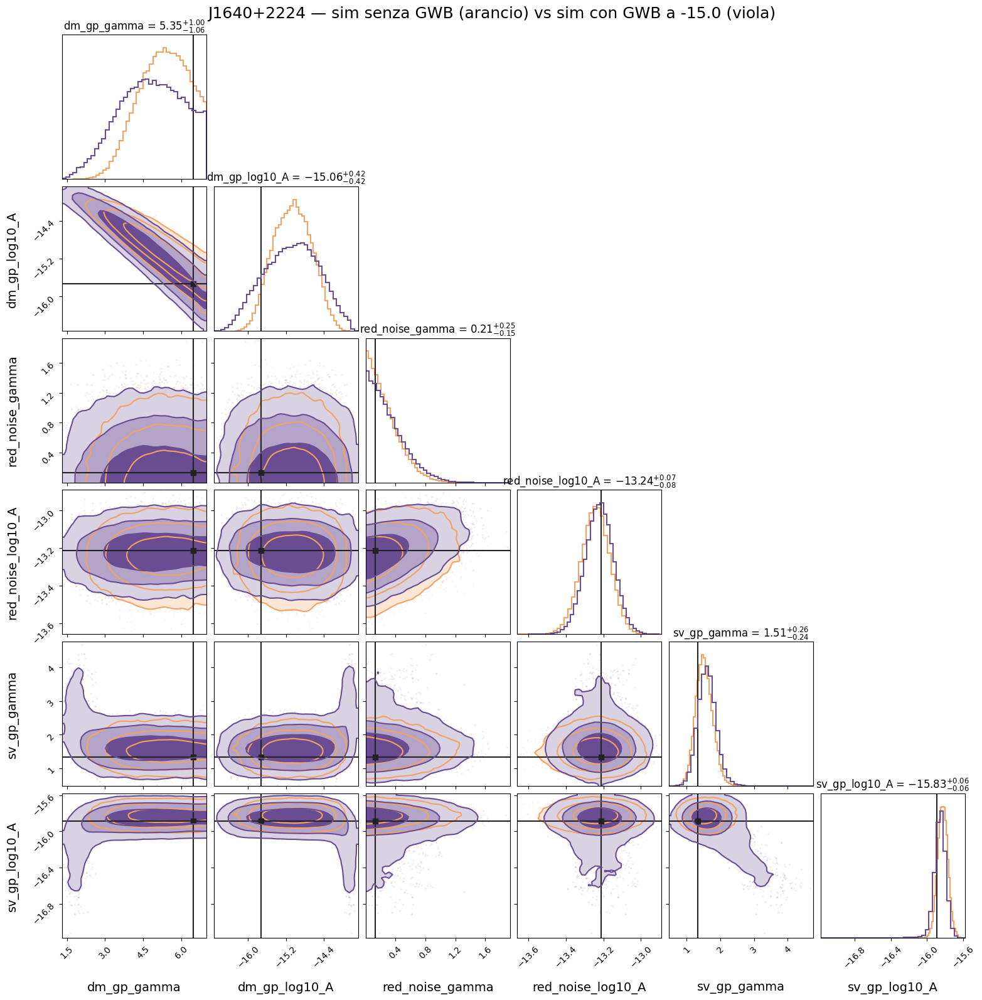

In [108]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_sim2,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A150,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim senza GWB (arancio) vs sim con GWB a -15.0 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_noGWB_vs_gwb_A150.png', dpi=150, bbox_inches='tight')

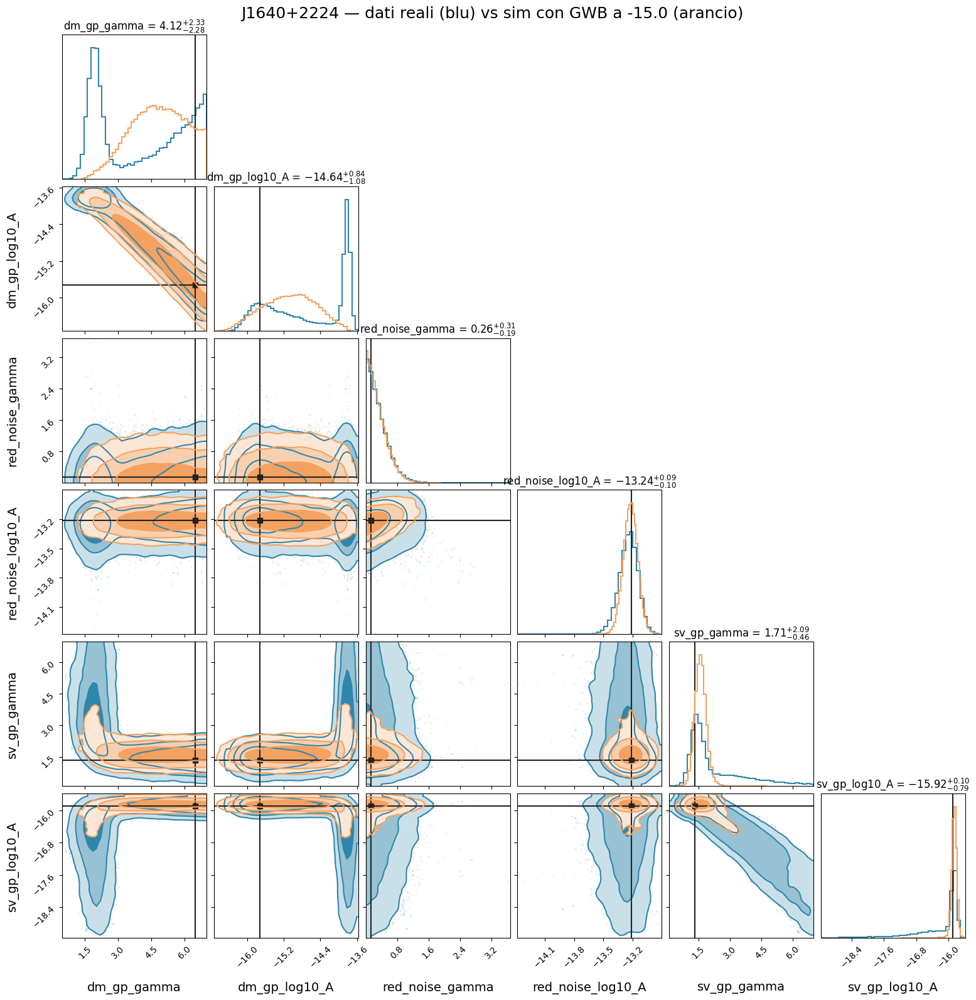

In [109]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A150,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — dati reali (blu) vs sim con GWB a -15.0 (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_reali_vs_sim_gwb_A150.png', dpi=150, bbox_inches='tight')

### GWB a -15.5

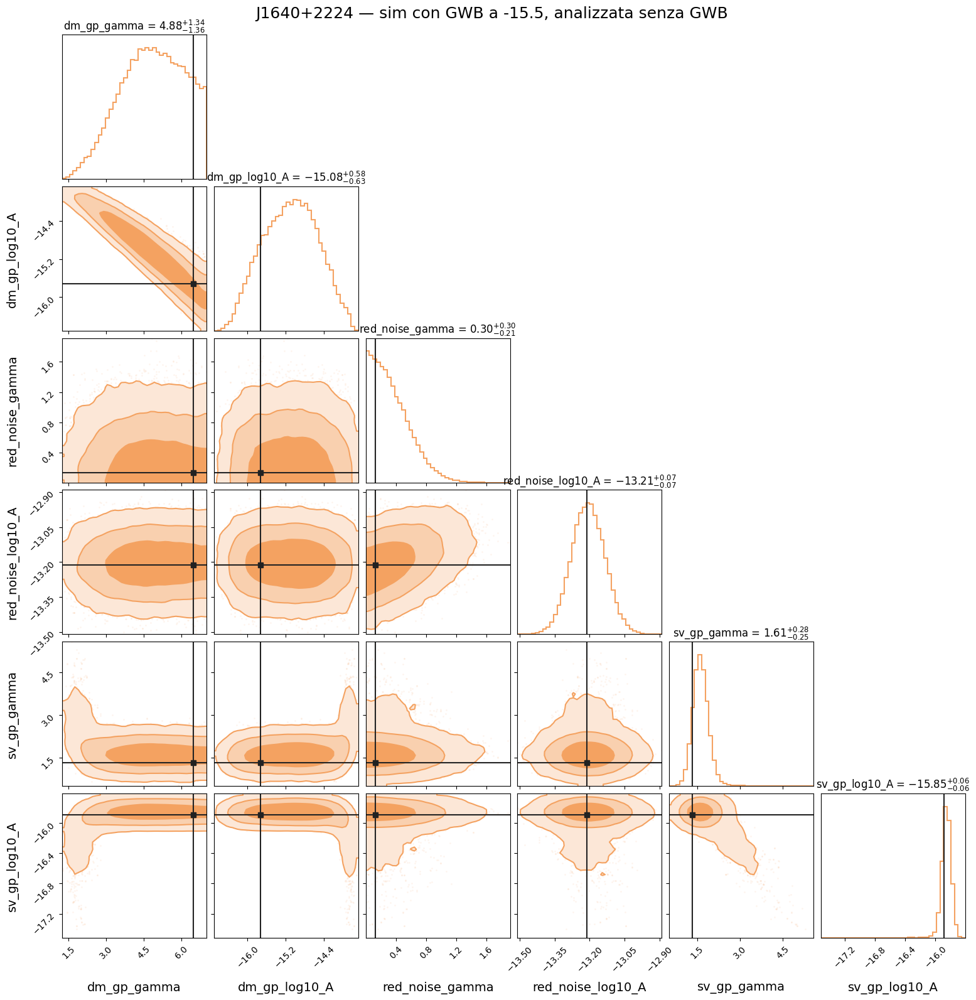

In [110]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

fig = corner.corner(
    chain_gwb_A155,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim con GWB a -15.5, analizzata senza GWB',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_gwb_A155.png', dpi=150, bbox_inches='tight')

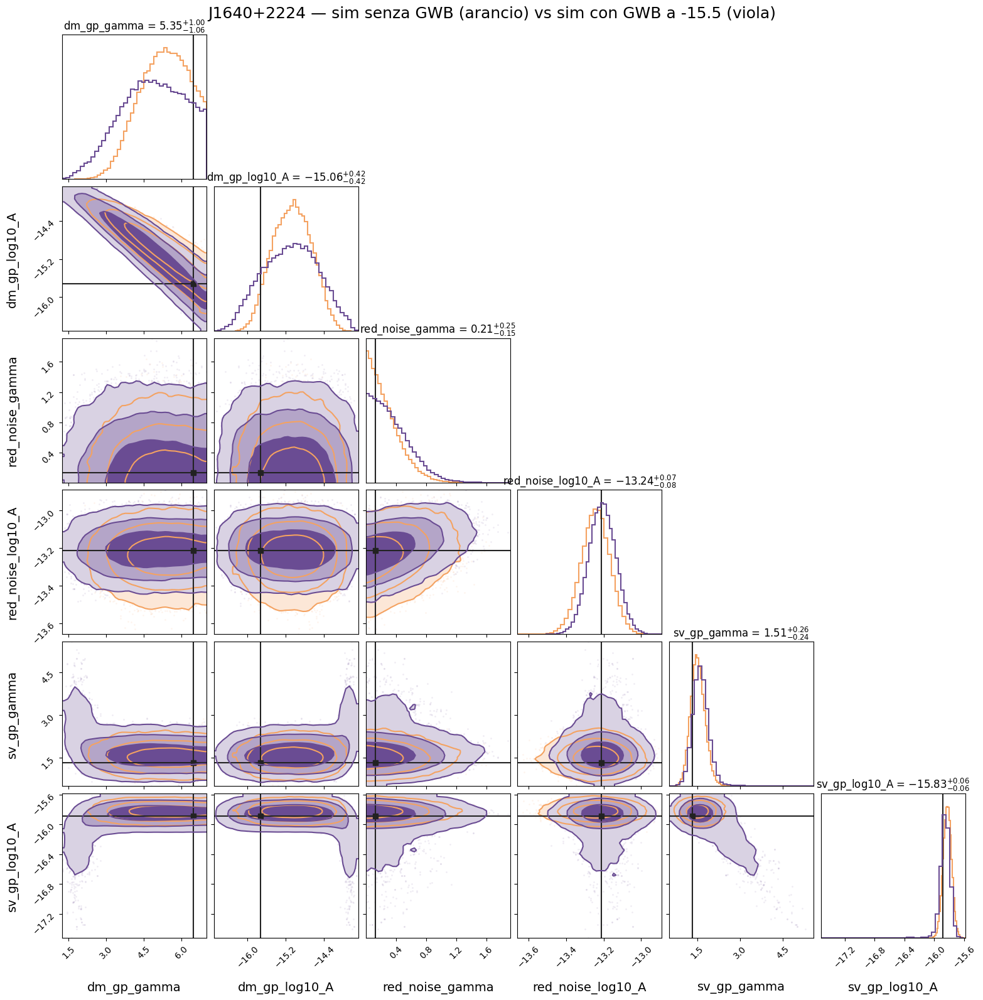

In [111]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_sim2,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A155,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — sim senza GWB (arancio) vs sim con GWB a -15.5 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_sim_noGWB_vs_gwb_A155.png', dpi=150, bbox_inches='tight')

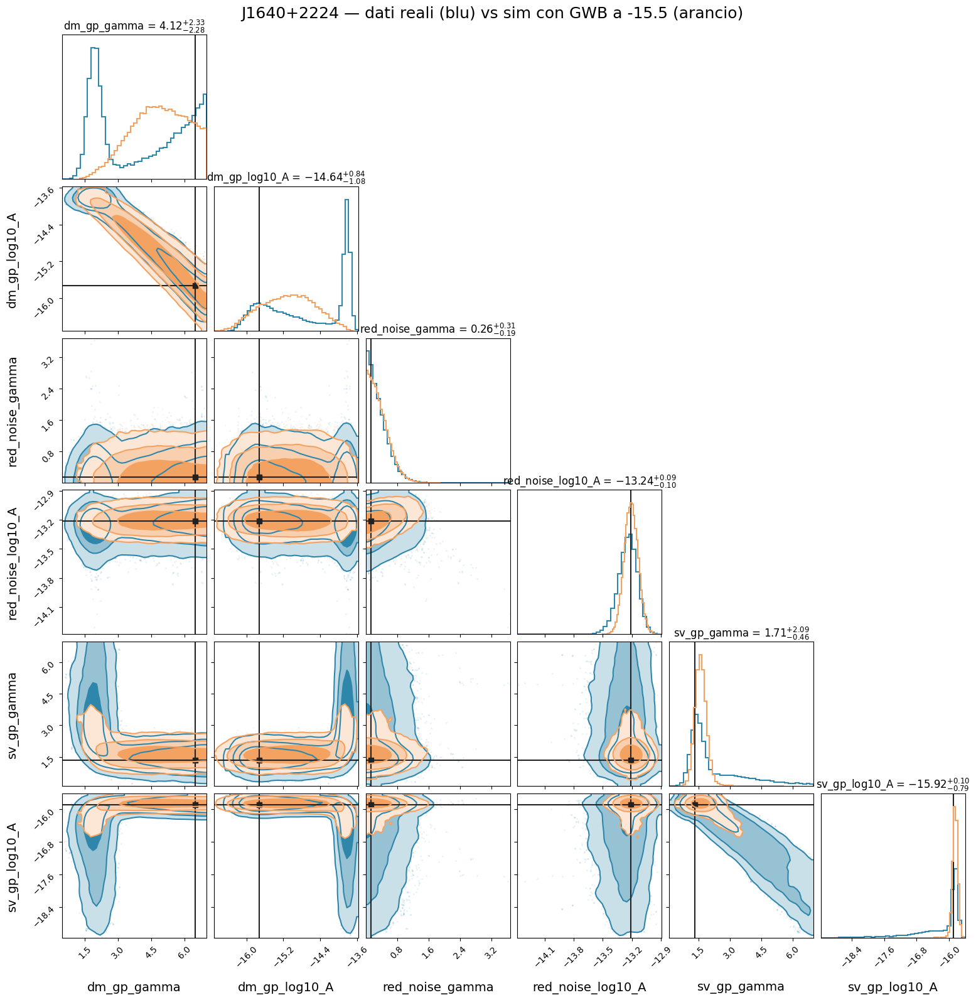

In [112]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwb_A155,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — dati reali (blu) vs sim con GWB a -15.5 (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/06_reali_vs_sim_gwb_A155.png', dpi=150, bbox_inches='tight')

## 7-8. Band noise a -13 e -12.5 (notebook 21)

Il grafico 6 par OFF vs band a -12.5 e anche il punto 8.

In [113]:
chain_off        = load_chain('./test_sim_bn_OFF_50comp/chain_1.txt')
chain_bn130_6par = load_chain('./test_sim_bn_A130_50comp/chain_1.txt')
chain_bn130_8par = load_chain('./test_sim_bn_A130_bnmodel/chain_1.txt')
chain_bn125_6par = load_chain('./test_sim_bn_A125_50comp/chain_1.txt')
chain_bn125_8par = load_chain('./test_sim_bn_A125_bnmodel/chain_1.txt')

### Band noise a -13.0

In [114]:
truths_bn130 = dict(truths_dict)
truths_bn130['J1640+2224_band_noise_gamma'] = 3.0
truths_bn130['J1640+2224_band_noise_log10_A'] = -13.0

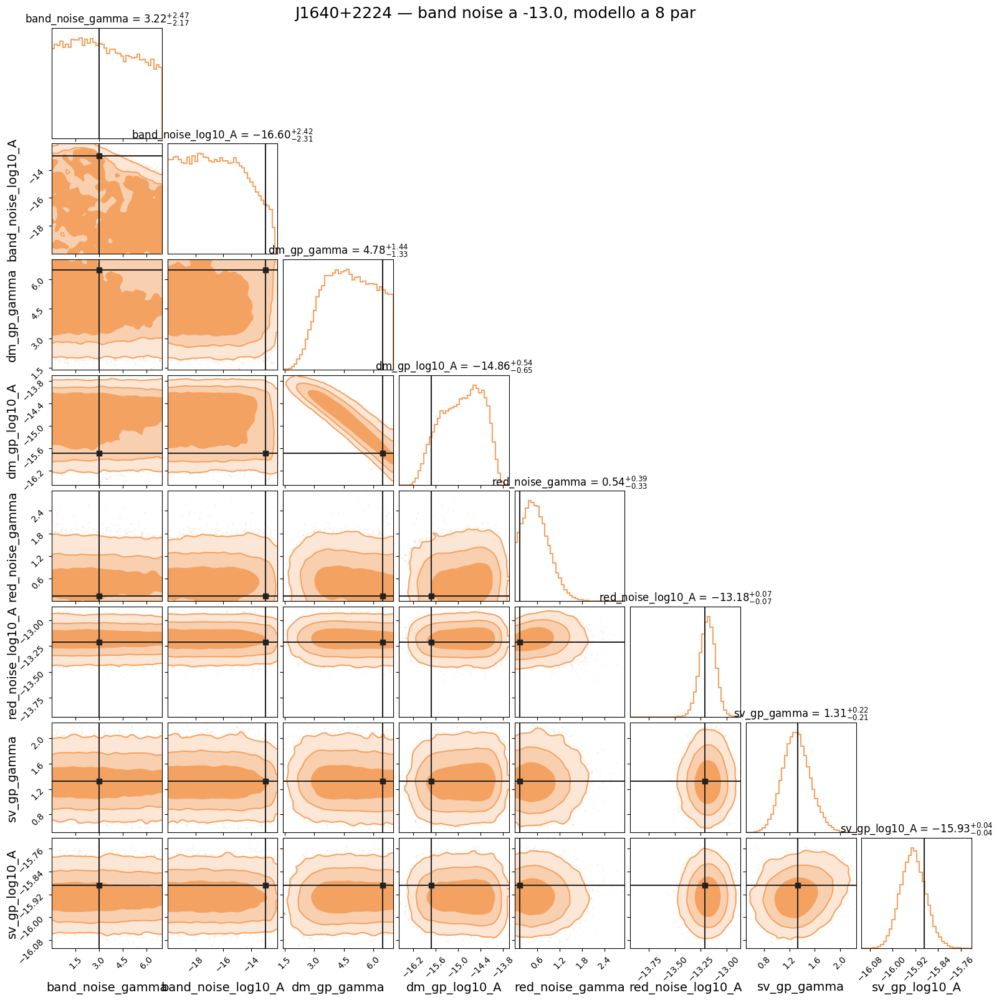

In [115]:
truth_values = [truths_bn130[p] for p in params_8]
clean_labels = [name.replace('J1640+2224_', '') for name in params_8]

fig = corner.corner(
    chain_bn130_8par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -13.0, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A130_8par.png', dpi=150, bbox_inches='tight')

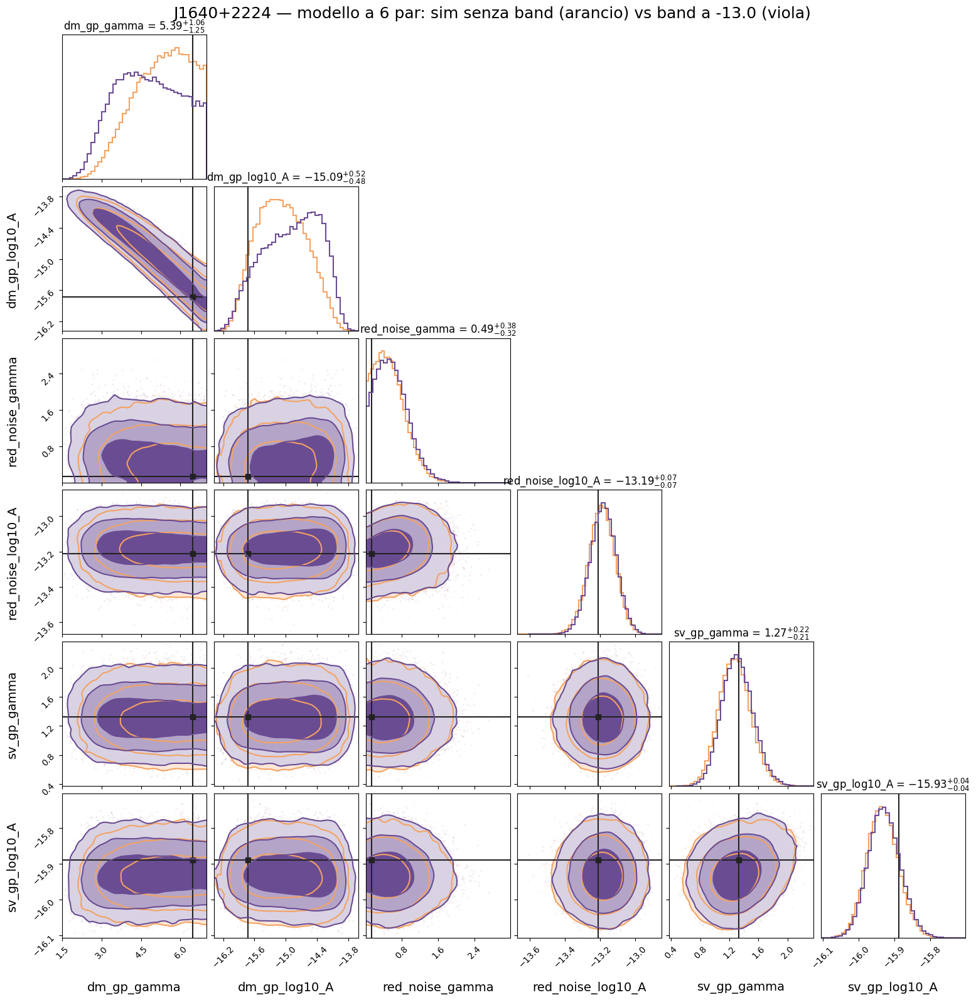

In [116]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_off,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn130_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: sim senza band (arancio) vs band a -13.0 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A130_6par_OFF_vs_band.png', dpi=150, bbox_inches='tight')

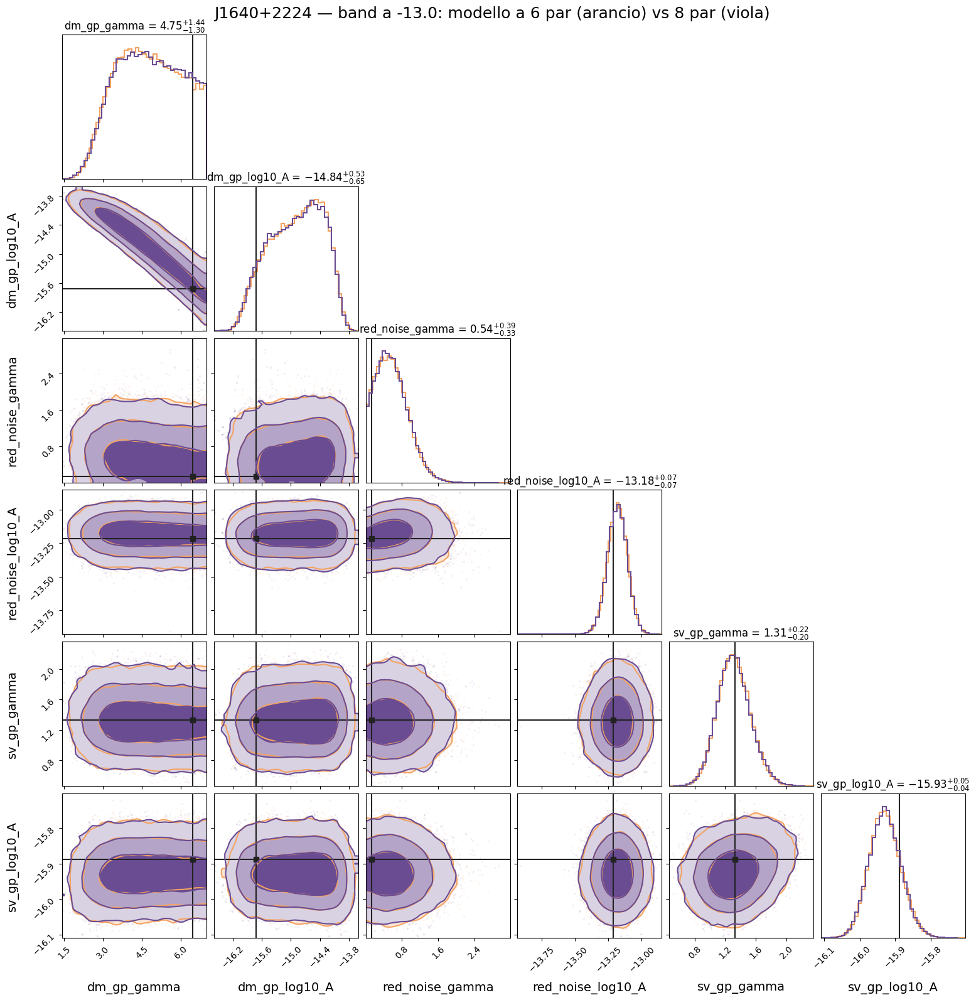

In [117]:
chain_bn130_8par_comuni = chain_bn130_8par[:, [params_8.index(p) for p in params_6]]

truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_bn130_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn130_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band a -13.0: modello a 6 par (arancio) vs 8 par (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A130_6par_vs_8par.png', dpi=150, bbox_inches='tight')

### Band noise a -12.5

In [118]:
truths_bn125 = dict(truths_dict)
truths_bn125['J1640+2224_band_noise_gamma'] = 3.0
truths_bn125['J1640+2224_band_noise_log10_A'] = -12.5

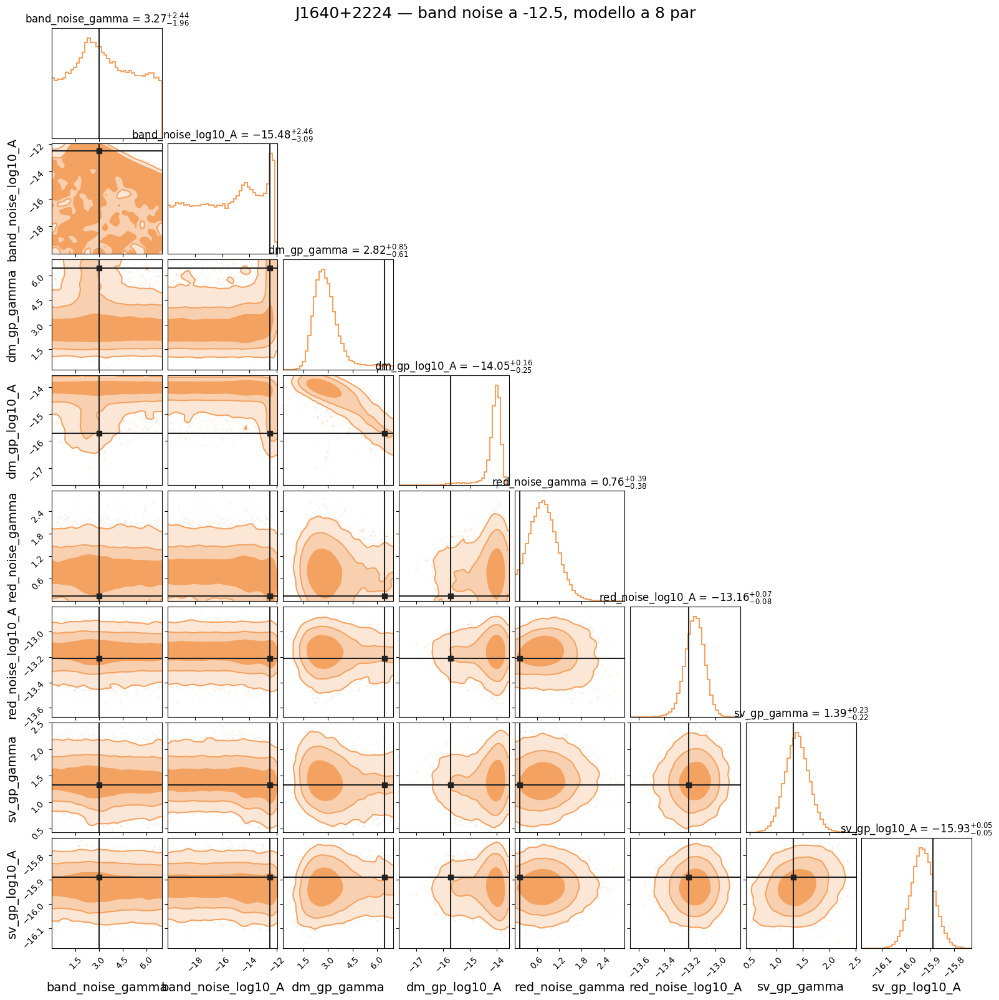

In [119]:
truth_values = [truths_bn125[p] for p in params_8]
clean_labels = [name.replace('J1640+2224_', '') for name in params_8]

fig = corner.corner(
    chain_bn125_8par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise a -12.5, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A125_8par.png', dpi=150, bbox_inches='tight')

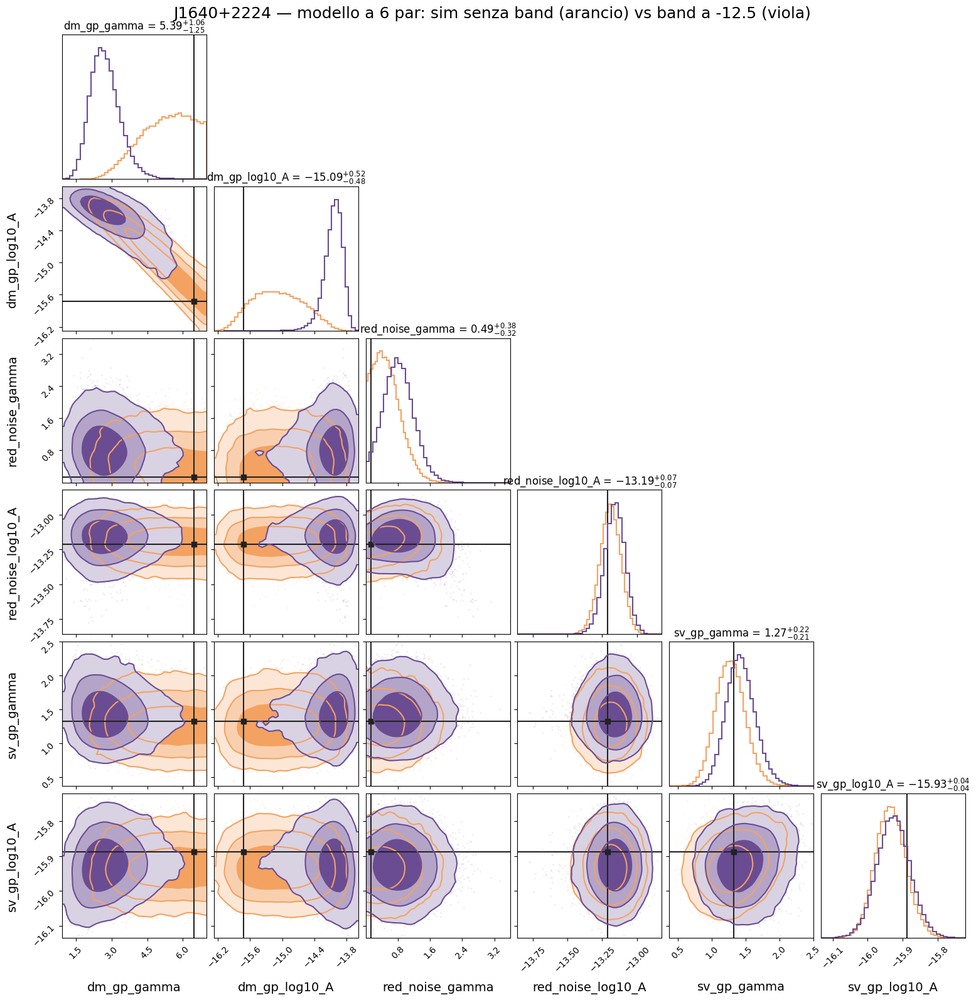

In [120]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_off,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn125_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: sim senza band (arancio) vs band a -12.5 (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A125_6par_OFF_vs_band.png', dpi=150, bbox_inches='tight')

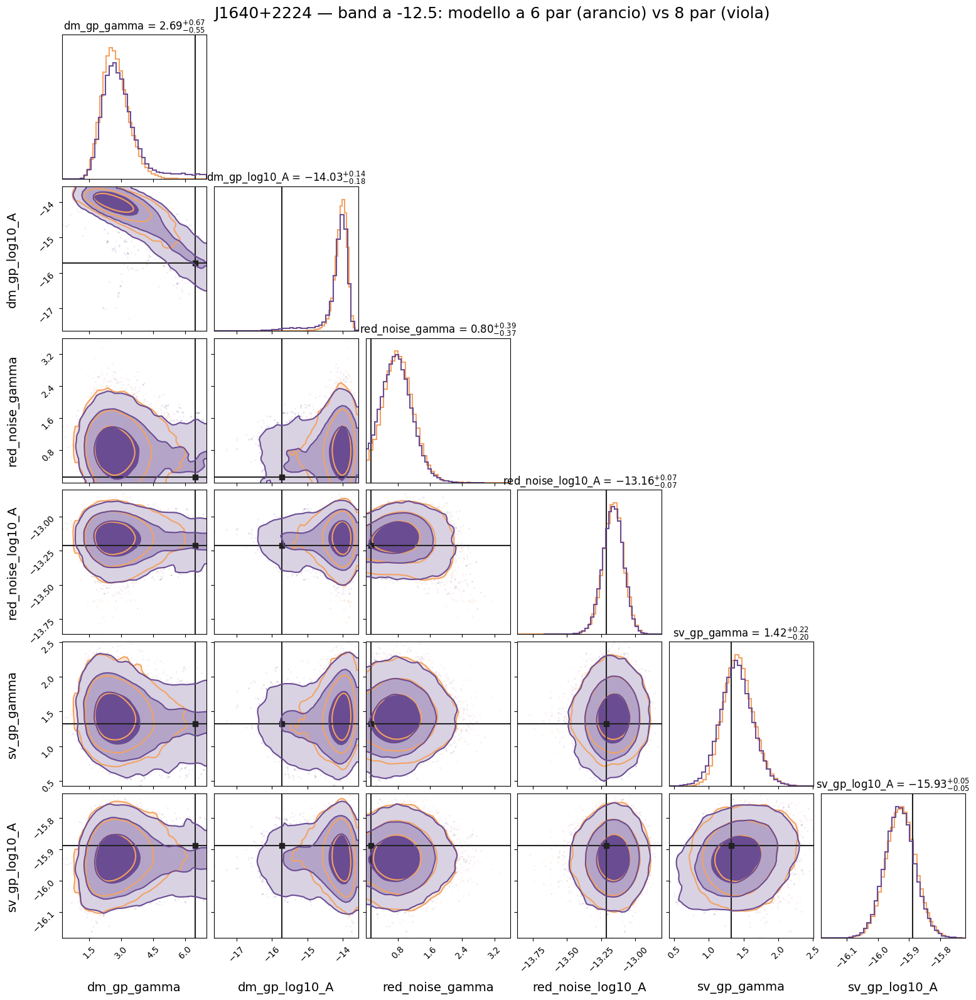

In [121]:
chain_bn125_8par_comuni = chain_bn125_8par[:, [params_8.index(p) for p in params_6]]

truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_bn125_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_bn125_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band a -12.5: modello a 6 par (arancio) vs 8 par (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/07_bn_A125_6par_vs_8par.png', dpi=150, bbox_inches='tight')

## 9. GWB a -14 + band noise a -12.3 (notebook 22)

In [122]:
chain_gwbbn_6par = load_chain('./test_sim_bn_A123_GWB_6par/chain_1.txt')
chain_gwbbn_8par = load_chain('./test_sim_bn_A123_GWB_8par/chain_1.txt')
print(chain_gwbbn_6par.shape, chain_gwbbn_8par.shape)

truths_gwbbn = dict(truths_dict)
truths_gwbbn['J1640+2224_band_noise_gamma'] = 3.0
truths_gwbbn['J1640+2224_band_noise_log10_A'] = -12.3

(75001, 6) (75001, 8)


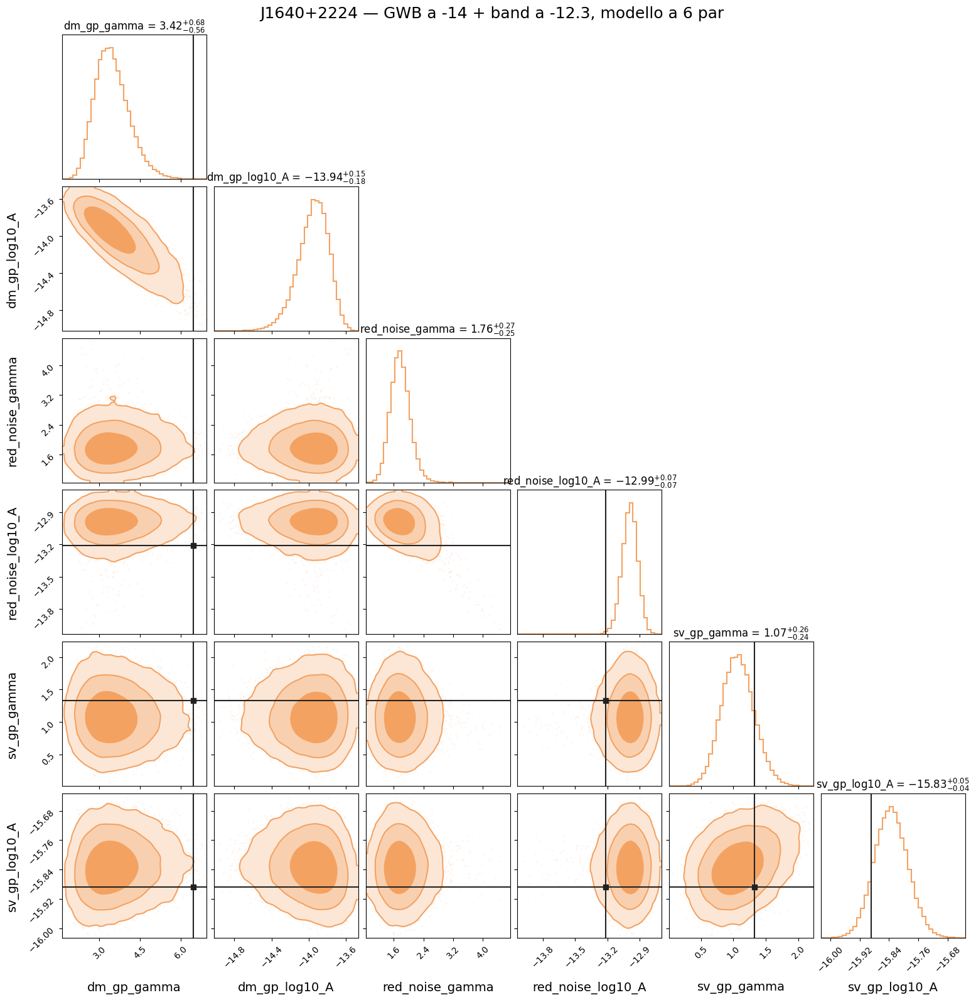

In [123]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

fig = corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB a -14 + band a -12.3, modello a 6 par',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_gwbbn_6par.png', dpi=150, bbox_inches='tight')

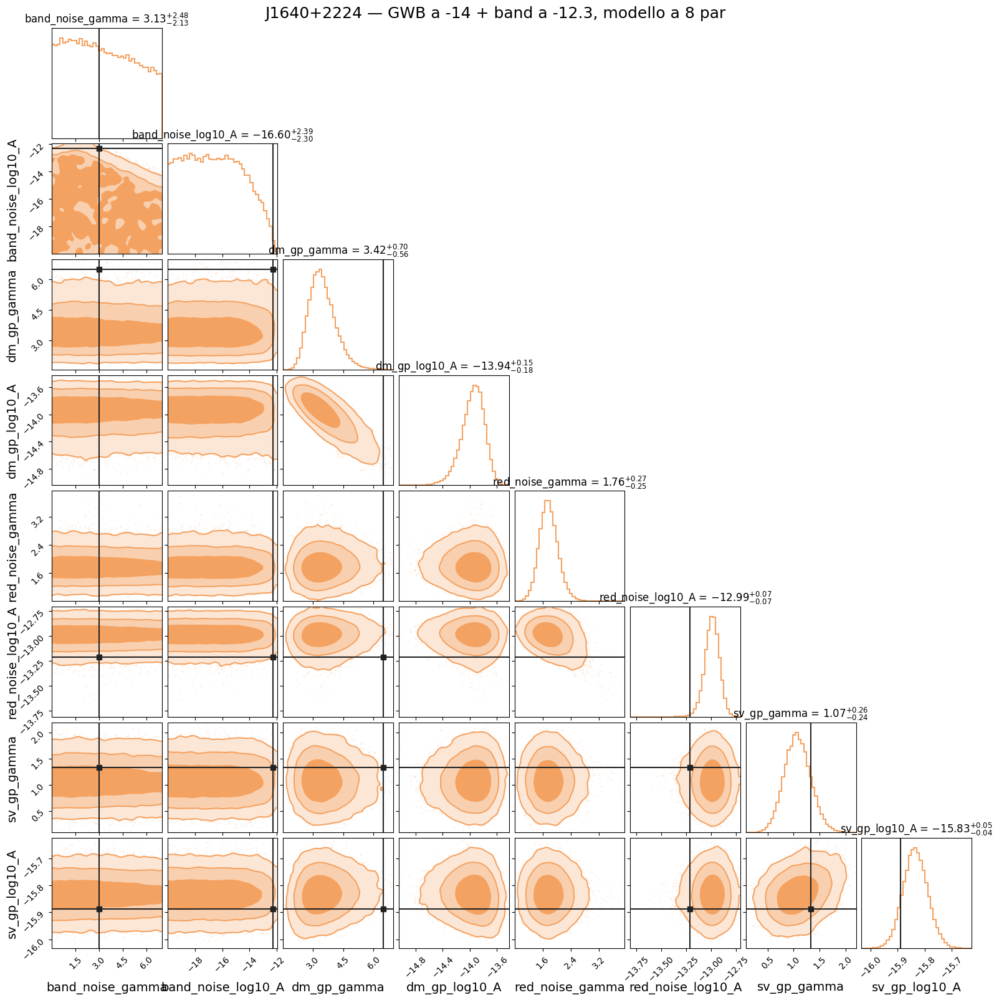

In [124]:
truth_values = [truths_gwbbn[p] for p in params_8]
clean_labels = [name.replace('J1640+2224_', '') for name in params_8]

fig = corner.corner(
    chain_gwbbn_8par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB a -14 + band a -12.3, modello a 8 par',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_gwbbn_8par.png', dpi=150, bbox_inches='tight')

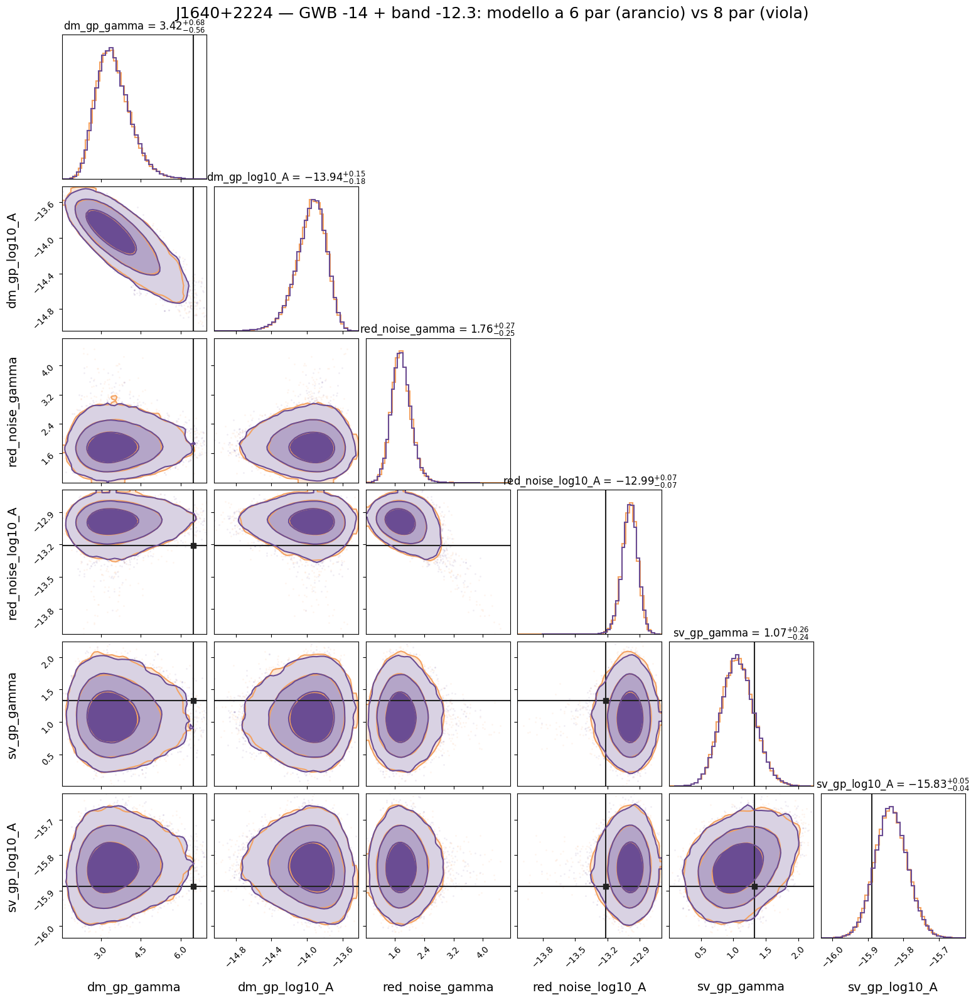

In [125]:
chain_gwbbn_8par_comuni = chain_gwbbn_8par[:, [params_8.index(p) for p in params_6]]

truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_8par_comuni,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — GWB -14 + band -12.3: modello a 6 par (arancio) vs 8 par (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_gwbbn_6par_vs_8par.png', dpi=150, bbox_inches='tight')

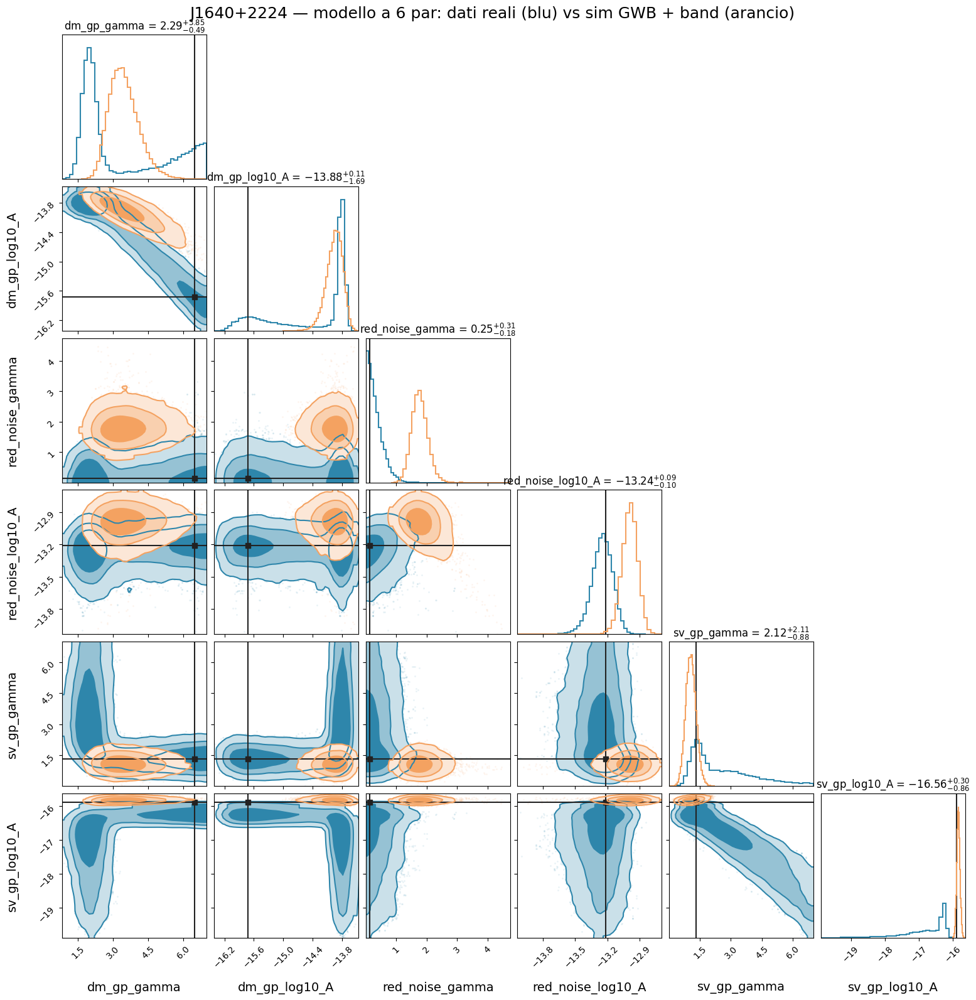

In [126]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_real_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: dati reali (blu) vs sim GWB + band (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_reali_vs_gwbbn_6par.png', dpi=150, bbox_inches='tight')

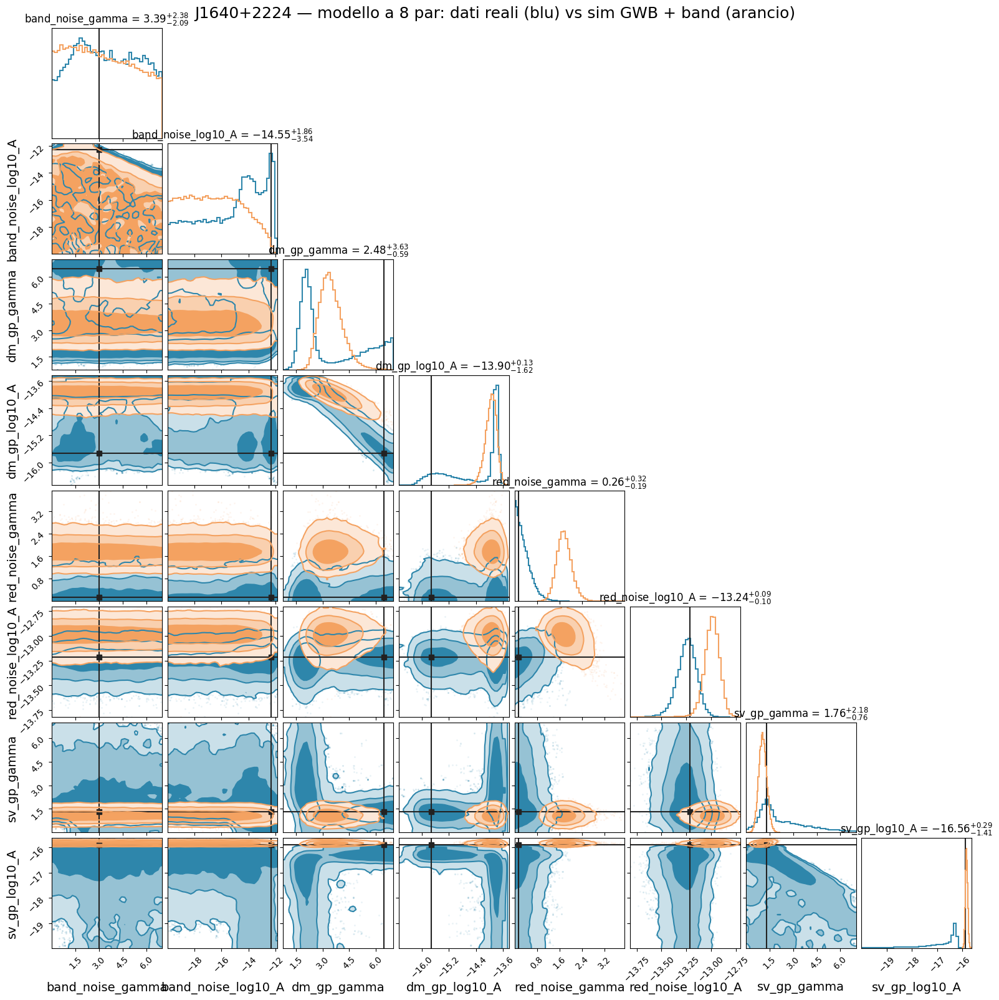

In [127]:
truth_values = [truths_gwbbn[p] for p in params_8]
clean_labels = [name.replace('J1640+2224_', '') for name in params_8]

# Primo corner
fig = corner.corner(
    chain_real_8par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=REALE,
    hist_kwargs={'color': REALE, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_8par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 8 par: dati reali (blu) vs sim GWB + band (arancio)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_reali_vs_gwbbn_8par.png', dpi=150, bbox_inches='tight')

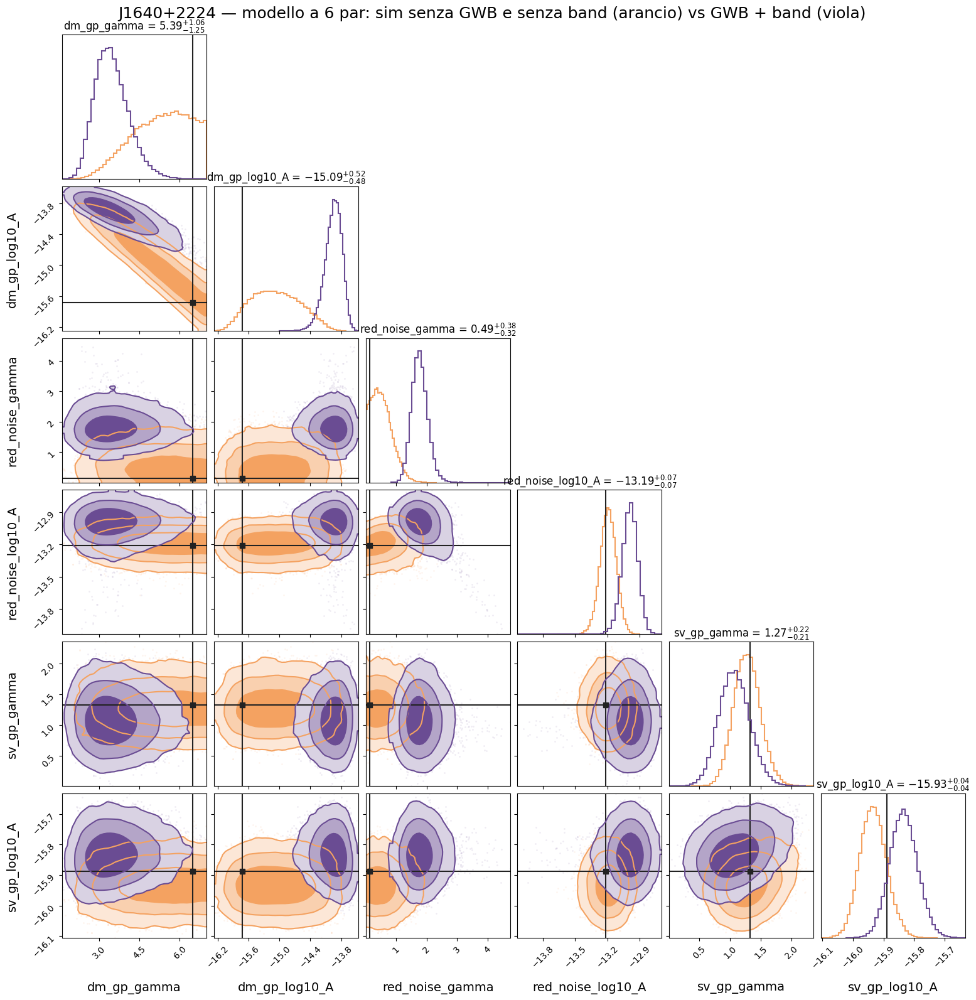

In [128]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_off,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: sim senza GWB e senza band (arancio) vs GWB + band (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_OFF_vs_gwbbn.png', dpi=150, bbox_inches='tight')

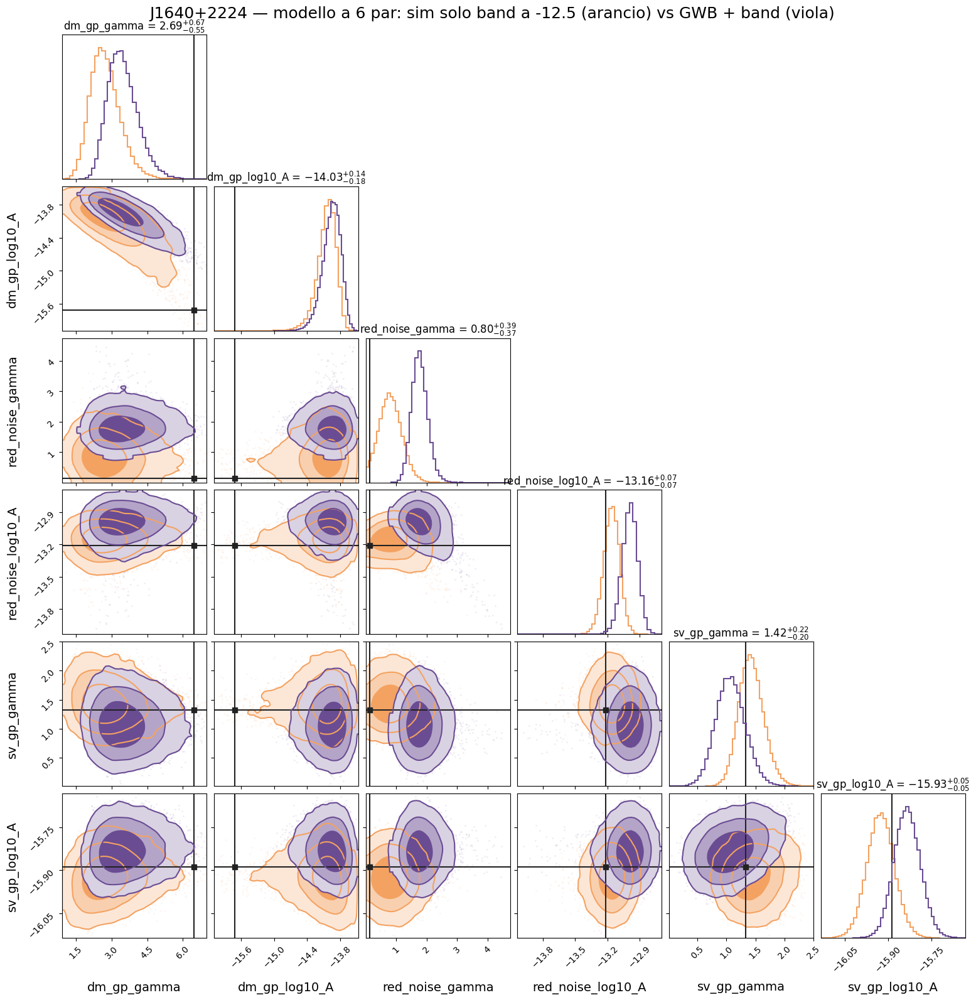

In [129]:
truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_bn125_6par,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: sim solo band a -12.5 (arancio) vs GWB + band (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_solobn125_vs_gwbbn.png', dpi=150, bbox_inches='tight')

### Solo GWB vs GWB + band

Solo dopo aver lanciato il sampling del notebook 12 (catena `test_gwb_A140_g433_sv44/`).

In [130]:
chain_gwb = load_chain('./test_gwb_A140_g433_sv44/chain_1.txt')

truth_values = [truths_dict[p] for p in params_6]
clean_labels = [name.replace('J1640+2224_', '') for name in params_6]

# Primo corner
fig = corner.corner(
    chain_gwb,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 12},
    color=SIM,
    hist_kwargs={'color': SIM, 'linewidth': 1.5 , "density": True},
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
)

# Secondo corner, sovrapposto
corner.corner(
    chain_gwbbn_6par,
    labels=clean_labels,
    show_titles=False,            # non serve mostrare i titoli due volte
    color=SIM_2,
    hist_kwargs={'color': SIM_2, 'linewidth': 1.5 , "density": True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    smooth1d=None,
    bins=40,
    fig=fig,
    scale_hist=False,
);

fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — modello a 6 par: sim solo GWB (arancio) vs GWB + band (viola)',
             fontsize=18, y=1.00)

fig.savefig('corner_tesi/09_soloGWB_vs_gwbbn.png', dpi=150, bbox_inches='tight')

FileNotFoundError: ./test_gwb_A140_g433_sv44/chain_1.txt not found.